# Near-Earth Asteroid Characterization and Potentially Hazardous Asteroid (PHA) Classification

**Research question.** How effectively can an asteroid's designated hazardous status be predicted from its observable kinematic close-approach behaviour and physical properties, and what trade-offs emerge when the directly defining threshold variables (H and MOID) are left out?

**Sources:** CAD (close-approach events), Sentry (impact-risk table), NeoWs (catalogue, orbital elements and the PHA label).

**Pipeline:** extraction → profiling → cleaning (with a cleaning log) → transformation → SQLite load with validation → insights → ML → exports for Power BI.

## 0. Setup

In [ ]:
# NASA API key (dummy key for now - hide this later!)
import os
os.environ["NASA_API_KEY"] = "dummy-key-for-now"

In [ ]:
# standard library imports
import re
import json
import gzip
import time
import random
import sqlite3
import warnings
from pathlib import Path
from datetime import datetime, timezone

In [ ]:
# data / plotting libraries
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

In [ ]:
# scikit-learn imports
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix,
                             precision_recall_curve, make_scorer)
from sklearn.inspection import permutation_importance

In [ ]:
# display settings
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60, "display.width", 200, "display.max_colwidth", 80)

In [ ]:
# Config: random seed, folders and API urls
SEED = 42
DATA_DIR = Path(os.environ.get("NEO_DATA_DIR", "neo_project_data"))
RAW_DIR = DATA_DIR / "raw"
CLEAN_DIR = DATA_DIR / "clean"
FIG_DIR = DATA_DIR / "figures"

for d in (RAW_DIR, CLEAN_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

NASA_API_KEY = os.environ.get("NASA_API_KEY", "DEMO_KEY")
CAD_URL = "https://ssd-api.jpl.nasa.gov/cad.api"
SENTRY_URL = "https://ssd-api.jpl.nasa.gov/sentry.api"
NEOWS_URL = "https://api.nasa.gov/neo/rest/v1/neo/browse"

In [ ]:
# Project parameters
CAD_START_YEAR = 1900
CAD_END_YEAR = 2100
CAD_DIST_MAX_AU = 0.05
NEOWS_PAGE_SIZE = 20
NEOWS_PAGES_TO_FETCH = 800
REQUEST_PAUSE_S = 0.4
MIN_ROWS_REQUIRED = 1000

# PHA definition according to NASA
PHA_H_MAX = 22.0
PHA_MOID_MAX = 0.05

# unit conversions
AU_KM = 149_597_870.7
LUNAR_KM = 384_400.0

In [ ]:
# Plot style and colours
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": .25,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
})
C_NON = "#5b7c99"
C_PHA = "#d9622b"

if NASA_API_KEY == "DEMO_KEY":
    print("API key in use:", "DEMO_KEY (too limited for NeoWs!)")
else:
    print("API key in use:", "custom key")

API key in use: custom key


## 1. Data extraction

### 1.1 Download helper

 One function does all the downloading. Every response is saved as a gzip file, so re-running the notebook reads from the cache instead of calling the API again.

In [ ]:
class RateLimitExhausted(RuntimeError):
    pass

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "neo-pha-wrangling-student-project/1.0"})
REQUEST_LOG = []

In [ ]:
def fetch_json_cached(url, params, cache_path, max_retries=5):
    """Return (json, 'cache'|'network'). Raw bytes are cached gzip-compressed, untouched."""
    cache_path = Path(cache_path)

    # if we already downloaded this, just read it from disk
    if cache_path.exists():
        with gzip.open(cache_path, "rt", encoding="utf-8") as f:
            return json.load(f), "cache"

    # otherwise download it (with retries)
    for attempt in range(1, max_retries + 1):
        try:
            r = SESSION.get(url, params=params, timeout=120)
        except requests.RequestException:
            time.sleep(min(2 ** attempt, 60))
            continue

        if r.status_code == 200:
            # save to a temporary file first, then rename
            cache_path.parent.mkdir(parents=True, exist_ok=True)
            tmp = cache_path.with_suffix(".tmp")
            with gzip.open(tmp, "wt", encoding="utf-8") as f:
                f.write(r.text)
            tmp.replace(cache_path)

            # log the request (without the api key)
            logged_params = {}
            for k, v in (params or {}).items():
                if k != "api_key":
                    logged_params[k] = v
            REQUEST_LOG.append({"url": url, "params": logged_params,
                                "status": 200, "at": datetime.now(timezone.utc).isoformat()})

            time.sleep(REQUEST_PAUSE_S)
            return r.json(), "network"

        # rate limit / server errors -> wait and try again
        if r.status_code in (429, 502, 503, 504):
            ra = r.headers.get("Retry-After", "")
            if ra.isdigit():
                wait = float(ra)
            else:
                wait = 20 * attempt
            time.sleep(min(wait, 120))
            continue

        r.raise_for_status()

    raise RateLimitExhausted(f"Gave up on {url} after {max_retries} attempts (rate limit?). Re-run later; cached pages are kept.")

### 1.2 CAD (close approaches) - one request per decade

In [ ]:
cad_frames = []
cad_sources = []

for y in range(CAD_START_YEAR, CAD_END_YEAR, 10):
    params = {"date-min": f"{y}-01-01", "date-max": f"{y+10}-01-01", "dist-max": CAD_DIST_MAX_AU,
              "body": "Earth", "fullname": "true", "diameter": "true"}
    cache_file = RAW_DIR / "cad" / f"cad_{y}_{y+10}_d{CAD_DIST_MAX_AU}.json.gz"

    js, src = fetch_json_cached(CAD_URL, params, cache_file)
    cad_sources.append(src)

    if js.get("data"):
        cad_frames.append(pd.DataFrame(js["data"], columns=js["fields"]))

cad_raw = pd.concat(cad_frames, ignore_index=True)
print("CAD rows:", len(cad_raw))

CAD rows: 43623


### 1.3 Sentry summary

In [ ]:
js, src = fetch_json_cached(SENTRY_URL, {}, RAW_DIR / "sentry" / "sentry_summary.json.gz")
sentry_raw = pd.DataFrame(js["data"])
print("Sentry rows:", len(sentry_raw))

Sentry rows: 2223


### 1.4 NeoWs

In [ ]:
def flatten_neo(o, page_no):
    # the JSON is nested, so pull out the pieces we need
    od = o.get("orbital_data") or {}
    ed = (o.get("estimated_diameter") or {}).get("kilometers") or {}
    ca = o.get("close_approach_data") or []

    keys = ["semi_major_axis", "eccentricity", "inclination", "perihelion_distance",
            "aphelion_distance", "orbital_period", "minimum_orbit_intersection",
            "data_arc_in_days", "observations_used", "orbit_uncertainty",
            "orbit_determination_date", "first_observation_date", "last_observation_date"]

    row = {
        "id": o.get("id"),
        "neo_reference_id": o.get("neo_reference_id"),
        "designation": o.get("designation"),
        "name": o.get("name"),
        "absolute_magnitude_h": o.get("absolute_magnitude_h"),
        "diameter_km_min": ed.get("estimated_diameter_min"),
        "diameter_km_max": ed.get("estimated_diameter_max"),
        "is_potentially_hazardous_asteroid": o.get("is_potentially_hazardous_asteroid"),
        "is_sentry_object": o.get("is_sentry_object"),
        "orbit_class_type": (od.get("orbit_class") or {}).get("orbit_class_type"),
        "n_ca_all_bodies": len(ca),
        "n_ca_earth": sum(1 for c in ca if c.get("orbiting_body") == "Earth"),
        "_page": page_no,
    }

    # add the orbital elements
    for k in keys:
        row[k] = od.get(k)
    return row

In [ ]:
def neows_page(n):
    params = {"page": n, "size": NEOWS_PAGE_SIZE, "api_key": NASA_API_KEY}
    cache_file = RAW_DIR / "neows" / f"browse_s{NEOWS_PAGE_SIZE}_p{n:05d}.json.gz"
    return fetch_json_cached(NEOWS_URL, params, cache_file)

In [ ]:
# first page tells us how many pages the catalogue has
first, _ = neows_page(0)
total_pages = first["page"]["total_pages"]
total_elements = first["page"]["total_elements"]
print("Catalogue size:", total_elements, "asteroids on", total_pages, "pages")

Catalogue size: 62746 asteroids on 3138 pages


In [ ]:
# pick which pages to download (seeded random sample so it is reproducible)
if NEOWS_PAGES_TO_FETCH is None or NEOWS_PAGES_TO_FETCH >= total_pages:
    pages = list(range(total_pages))
else:
    pages = sorted(random.Random(SEED).sample(range(total_pages), NEOWS_PAGES_TO_FETCH))
print("Pages to read:", len(pages))

Pages to read: 800


In [ ]:
records = []
pages_done = 0
stopped_early = False

for i, p in enumerate(pages):
    try:
        js, _ = neows_page(p)
    except RateLimitExhausted as e:
        print("STOPPED EARLY:", e)
        stopped_early = True
        break

    records += [flatten_neo(o, p) for o in js["near_earth_objects"]]
    pages_done += 1

    if (i + 1) % 100 == 0:
        print(f"  NeoWs pages read: {i+1}/{len(pages)}")

neows_raw = pd.DataFrame(records)

  NeoWs pages read: 100/800
  NeoWs pages read: 200/800
  NeoWs pages read: 300/800
  NeoWs pages read: 400/800
  NeoWs pages read: 500/800
  NeoWs pages read: 600/800
  NeoWs pages read: 700/800
  NeoWs pages read: 800/800


### 1.5 Save a manifest of what was pulled

In [ ]:
manifest = {
    "pulled_at_utc": datetime.now(timezone.utc).isoformat(),
    "cad": {"decades": len(cad_sources), "rows": len(cad_raw),
            "from_cache": cad_sources.count("cache"), "dist_max_au": CAD_DIST_MAX_AU},
    "sentry": {"rows": len(sentry_raw)},
    "neows": {"catalogue_total": total_elements, "pages_fetched": pages_done,
              "rows": len(neows_raw), "stopped_early": stopped_early},
    "network_requests_this_run": len(REQUEST_LOG),
}

(RAW_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))

assert len(neows_raw) >= MIN_ROWS_REQUIRED, "Fewer than 1,000 NeoWs rows."

{
  "pulled_at_utc": "2026-10-19T05:44:38.483860+00:00",
  "cad": {
    "decades": 20,
    "rows": 43623,
    "from_cache": 20,
    "dist_max_au": 0.05
  },
  "sentry": {
    "rows": 2223
  },
  "neows": {
    "catalogue_total": 62746,
    "pages_fetched": 800,
    "rows": 16000,
    "stopped_early": false
  },
  "network_requests_this_run": 0
}


## 2. Raw-data profiling

Before changing anything, record what the raw tables look like. This is the "before" picture for the cleaning log.

In [ ]:
def profile(df, name):
    return {
        "table": name,
        "rows": len(df),
        "columns": df.shape[1],
        "exact_duplicate_rows": int(df.duplicated().sum()),
        "cells_missing_%": round(100 * df.isna().mean().mean(), 2),
        "text_columns": int(sum(d == object or pd.api.types.is_string_dtype(d) for d in df.dtypes)),
    }

In [ ]:
# overall summary of the three raw tables
raw_profile = pd.DataFrame([
    profile(cad_raw, "CAD raw"),
    profile(sentry_raw, "Sentry raw"),
    profile(neows_raw, "NeoWs raw (flattened)"),
])
display(raw_profile)

,table,rows,columns,exact_duplicate_rows,cells_missing_%,text_columns
0,CAD raw,43623,14,0,13.97,14
1,Sentry raw,2223,14,0,0.01,13
2,NeoWs raw (flattened),16000,26,0,0.12,16


In [ ]:
print("CAD dtypes:")
display(cad_raw.dtypes.to_frame("dtype").T)

CAD dtypes:


,des,orbit_id,jd,cd,dist,dist_min,dist_max,v_rel,v_inf,t_sigma_f,h,diameter,diameter_sigma,fullname
dtype,object,object,object,object,object,object,object,object,object,object,object,object,object,object


In [ ]:
print("Share missing by column, columns with any missing values:")
miss = pd.concat({
    "CAD": cad_raw.isna().mean(),
    "Sentry": sentry_raw.isna().mean(),
    "NeoWs": neows_raw.isna().mean(),
}).rename("share_missing")
display(miss[miss > 0].round(4).to_frame())

Share missing by column, columns with any missing values:


share_missing
CAD    v_inf                              0.0005
       h                                  0.0002
       diameter                           0.9764
       diameter_sigma                     0.9788
Sentry ts_max                             0.0009
NeoWs  designation                        0.0001
       name                               0.0001
       absolute_magnitude_h               0.0002
       diameter_km_min                    0.0002
       diameter_km_max                    0.0002
       orbit_class_type                   0.0001
       semi_major_axis                    0.0001
       eccentricity                       0.0001
       inclination                        0.0001
       perihelion_distance                0.0001
       aphelion_distance                  0.0001
       orbital_period                     0.0001
       minimum_orbit_intersection         0.0098
       data_arc_in_days                   0.0103
       observations_used                  0.0001
       orbit_uncertainty                  0.0001
       orbit_determination_date           0.0098
       first_observation_date             0.0001
       last_observation_date              0.0001

In [ ]:
cad_raw.head()


,des,orbit_id,jd,cd,dist,dist_min,dist_max,v_rel,v_inf,t_sigma_f,h,diameter,diameter_sigma,fullname
0,509352,64,2415024.433813976,1900-Jan-04 22:25,0.00963195025335591,0.00962523562960666,0.00963866638925279,8.68671003818195,8.6548063383014,00:02,20.14,None,None,509352 (2007 AG)
1,2014 SC324,57,2415030.546589490,1900-Jan-11 01:07,0.0399643614742356,0.0399037242628346,0.0400250873224976,10.6523824305679,10.6461217669474,00:18,24.39,None,None,(2014 SC324)
2,2012 UK171,54,2415032.460046467,1900-Jan-12 23:02,0.0497058599097771,0.0495777447701907,0.0498339905241157,7.15349625845258,7.14599880015143,00:05,24.46,None,None,(2012 UK171)
3,2024 BA5,3,2415044.765225018,1900-Jan-25 06:22,0.0264339059058202,0.0113104808795275,0.198643997537703,8.43620373814833,8.42424702441644,21:33,26.02,None,None,(2024 BA5)
4,2024 BW1,6,2415045.311608766,1900-Jan-25 19:29,0.0379785045836797,0.0101250361433664,0.0894364785643446,6.33978714948284,6.32871124117805,4_11:16,25.12,None,None,(2024 BW1)


In [ ]:
sentry_raw.head()

,last_obs_jd,fullname,des,ip,ts_max,h,ps_max,n_imp,id,range,ps_cum,last_obs,v_inf,diameter
0,2456304.5,(2011 TO),2011 TO,2.937e-06,0,26.32,-6.15,1,bK11T00O,2064-2064,-6.15,2013-01-12,8.55,0.018
1,2455978.5,(2012 BA102),2012 BA102,1.22522146e-05,0,26.51,-6.27,20,bK12BA2A,2103-2122,-6.03,2012-02-21,7.21203952320587,0.017
2,2456774.5,(2014 HN197),2014 HN197,6.5351e-09,0,19.92,-5.98,12,bK14HJ7N,2069-2118,-5.50,2014-04-27,21.9988508209515,0.35
3,2454886.5,(2009 DV),2009 DV,3.1018e-08,0,24.86,-7.37,2,bK09D00V,2044-2102,-7.24,2009-02-24,22.0982648784577,0.036
4,2454895.5,(2009 EH1),2009 EH1,5.902e-10,0,27.85,-10.56,1,bK09E01H,2068-2068,-10.56,2009-03-05,10.69,0.0091


In [ ]:
neows_raw.head()

,id,neo_reference_id,designation,name,absolute_magnitude_h,diameter_km_min,diameter_km_max,is_potentially_hazardous_asteroid,is_sentry_object,orbit_class_type,n_ca_all_bodies,n_ca_earth,_page,semi_major_axis,eccentricity,inclination,perihelion_distance,aphelion_distance,orbital_period,minimum_orbit_intersection,data_arc_in_days,observations_used,orbit_uncertainty,orbit_determination_date,first_observation_date,last_observation_date
0,2002059,2002059,2059,2059 Baboquivari (1963 UA),16.05,1.638910,3.664713,False,False,AMO,7,0,1,2.642125049017742,.5314016016636036,11.01873885953402,1.238095566174187,4.046154531861297,1568.658761683946,.245255,22830.0,1561.0,0,2026-06-27 06:19:58,1963-11-09,2026-05-12
1,2002062,2002062,2062,2062 Aten (1976 AA),17.11,1.005900,2.249262,False,False,ATE,128,109,1,.9669667478344453,.1828582815030813,18.93555636228816,.7901488700548153,1.143784625614075,347.3087592635159,.113307,23339.0,1024.0,0,2021-05-24 18:22:09,1955-12-17,2019-11-10
2,2002329,2002329,2329,2329 Orthos (1976 WA),14.57,3.240074,7.245027,False,False,APO,14,8,1,2.412437431614276,.6532406969716966,24.49648504200215,.8365351223859566,3.988339740842596,1368.618841294837,.0936745,18174.0,1999.0,0,2026-03-05 05:17:39,1976-05-31,2026-03-04
3,2001221,2001221,1221,1221 Amor (1932 EA1),17.37,0.892391,1.995446,False,False,AMO,20,20,1,1.919716404453958,.4347308670361279,11.8701297472913,1.085156427482211,2.754276381425704,971.5251348763778,.10902,34548.0,734.0,0,2026-10-14 06:56:34,1932-03-12,2026-10-13
4,2001566,2001566,1566,1566 Icarus (1949 MA),16.53,1.313878,2.937920,True,False,APO,50,18,1,1.077994212576463,.8270188506942974,22.8016402405493,.1864726778363724,1.969515747316553,408.8114685792443,.0338047,28192.0,1796.0,0,2026-09-08 06:21:03,1949-07-01,2026-09-07


## 3. Data cleaning

Each step is recorded through `log_step`: what was found, what was done (**drop / convert / impute / flag / keep**) and why.

### 3.1 Cleaning log and helper functions

In [ ]:
CLEANING_LOG = []

def log_step(source, issue, found, action, why):
    CLEANING_LOG.append({
        "step": len(CLEANING_LOG) + 1,
        "source": source,
        "issue_found": issue,
        "count": int(found),
        "action": action,
        "rationale": why,
    })

In [ ]:
def norm_des(s):
    """Canonical join key: upper-case, collapsed whitespace, outer parentheses removed."""
    if pd.isna(s):
        return np.nan
    s = re.sub(r"\s+", " ", str(s)).strip().strip("()").strip().upper()
    return s or np.nan

In [ ]:
def to_flag(x):
    # turns True/False or "true"/"false" text into 1/0
    if isinstance(x, str):
        x = x.strip().lower() in ("true", "1", "yes")
    if pd.isna(x):
        return np.nan
    return int(bool(x))

In [ ]:
# month names -> numbers so date parsing does not depend on the computer's language
MONTHS = {m: f"{i:02d}" for i, m in enumerate(
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], 1)}

def parse_cd(series):
    s = series.astype("string").str.strip()
    for m, n in MONTHS.items():
        s = s.str.replace(f"-{m}-", f"-{n}-", regex=False)
    return pd.to_datetime(s, format="%Y-%m-%d %H:%M", errors="coerce")

In [ ]:
def parse_tsigma_minutes(x):
    if pd.isna(x):
        return np.nan
    t = str(x).strip().lstrip("<>~ ").strip()
    m = re.fullmatch(r"(?:(\d+)_)?(\d{1,2}):(\d{2})", t)
    if m:
        return int(m.group(1) or 0) * 1440 + int(m.group(2)) * 60 + int(m.group(3))
    return np.nan

### 3.2 Clean CAD

In [ ]:
cad = cad_raw.copy()
cad.columns = [c.strip() for c in cad.columns]
n0 = len(cad)

In [ ]:
# convert numeric columns (they arrive as strings)
num_cols = []
for c in ["orbit_id", "jd", "dist", "dist_min", "dist_max", "v_rel", "v_inf", "h", "diameter", "diameter_sigma"]:
    if c in cad.columns:
        num_cols.append(c)

before = cad[num_cols].isna().sum().sum()
for c in num_cols:
    cad[c] = pd.to_numeric(cad[c], errors="coerce")
after = cad[num_cols].isna().sum().sum()

log_step("CAD", "All numeric fields delivered as strings", len(num_cols), "convert",
         f"to_numeric with errors='coerce'; {int(after - before)} values became NaN through failed parsing, so no hidden type damage.")

In [ ]:
# strip whitespace from the name columns and build the join key
for c in ("des", "fullname"):
    cad[c] = cad[c].astype("string").str.strip()

log_step("CAD", "Leading whitespace in fullname (e.g. '       (2020 AY1)')", cad["fullname"].notna().sum(), "convert",
         "strip(); harmless but breaks string joins and slicers.")

cad["des_norm"] = cad["des"].map(norm_des)

In [ ]:
# parse the date strings and cross-check them against the Julian date column
cad["cd_dt"] = parse_cd(cad["cd"])
bad_dt = cad["cd_dt"].isna().sum()

jd_dt = pd.Timestamp("1858-11-17") + pd.to_timedelta(cad["jd"] - 2400000.5, unit="D")
mismatch = ((cad["cd_dt"] - jd_dt).abs() > pd.Timedelta(minutes=2)).sum()

log_step("CAD", "Date strings like '2020-Jan-01 00:54' (TDB time scale, English month names)", len(cad), "convert",
         f"Parsed to datetime ({int(bad_dt)} failed to parse); cross-checked against the Julian-date column: {int(mismatch)} rows differ by more than 2 min. Times stay in TDB (about 69 s ahead of UTC) because sub-minute precision does not matter at decade level.")

cad["year"] = cad["cd_dt"].dt.year
cad["decade"] = (cad["year"] // 10) * 10

In [ ]:
# t_sigma_f -> minutes
cad["t_sigma_minutes"] = cad["t_sigma_f"].map(parse_tsigma_minutes)
unparsed = (cad["t_sigma_f"].notna() & cad["t_sigma_minutes"].isna()).sum()

log_step("CAD", "t_sigma_f is a formatted text field ('< 00:01', 'dd_hh:mm', '~...')", unparsed, "convert / keep NaN",
         "Parsed to minutes; the '<' and '~' qualifiers are dropped. Unparseable values become NaN rather than guesses. Not used in the model.")

In [ ]:
# drop rows that cannot be used
need = ["des_norm", "dist", "v_rel", "cd_dt"]
unusable = cad[need].isna().any(axis=1).sum()
cad = cad.dropna(subset=need)

log_step("CAD", "Rows missing designation, distance, velocity or date", unusable, "drop",
         "Cannot be attributed to an asteroid or used for any feature.")

In [ ]:
# drop duplicate close approaches
dups = cad.duplicated(["des_norm", "jd"]).sum()
cad = cad.drop_duplicates(["des_norm", "jd"], keep="first")

log_step("CAD", "Duplicate close approaches (same asteroid and same Julian date; decade windows share a boundary)", dups, "drop",
         "Keep first; an event cannot happen twice and would inflate approach counts.")

In [ ]:
# flag suspicious values (but keep them)
tol = 1e-9
cad["flag_dist_order"] = ~((cad["dist_min"] - tol <= cad["dist"]) & (cad["dist"] <= cad["dist_max"] + tol))
cad["flag_bad_value"] = (cad["dist"] <= 0) | (cad["v_rel"] <= 0) | (cad["v_rel"] > 72.8)

log_step("CAD", "dist outside its own [dist_min, dist_max] interval", cad["flag_dist_order"].sum(), "flag",
         "Kept: may be rounding; flagged so dashboards can exclude them.")
log_step("CAD", "Non-positive distance or velocity, or v_rel above 72.8 km/s (physical maximum for a bound Solar System object hitting Earth)", cad["flag_bad_value"].sum(), "flag",
         "Kept and flagged rather than deleted: extreme values need a physical explanation before being removed.")

In [ ]:
# new column: distance in lunar distances
cad["dist_ld"] = cad["dist"] * AU_KM / LUNAR_KM

log_step("CAD", "Distances only in au", len(cad), "derive",
         "Added lunar-distance column (au x 149.6M km / 384,400 km) because it is the unit non-specialists recognise.")

cad = cad.reset_index(drop=True)
print(f"CAD: {n0:,} raw rows -> {len(cad):,} clean rows")

CAD: 43,623 raw rows -> 43,623 clean rows


### 3.3 Clean Sentry

In [ ]:
sentry = sentry_raw.copy()
s0 = len(sentry)

# numeric conversion
sentry_num_cols = []
for c in ["ip", "ps_cum", "ps_max", "ts_max", "v_inf", "diameter", "h", "last_obs_jd", "n_imp"]:
    if c in sentry.columns:
        sentry_num_cols.append(c)

for c in sentry_num_cols:
    sentry[c] = pd.to_numeric(sentry[c], errors="coerce")

log_step("Sentry", "Numeric fields delivered as strings", len(sentry_num_cols), "convert", "to_numeric(errors='coerce').")

In [ ]:
# join key and dates
sentry["des_norm"] = sentry["des"].map(norm_des)
sentry["last_obs"] = pd.to_datetime(sentry["last_obs"], errors="coerce")

In [ ]:
# split the impact window text '2064-2064' into start and end year
impact_range = sentry["range"].astype("string").str.extract(r"(\d{4})-(\d{4})").astype(float)
sentry["impact_year_start"] = impact_range[0]
sentry["impact_year_end"] = impact_range[1]

log_step("Sentry", "Impact window stored as text '2064-2064'", impact_range[0].notna().sum(), "convert",
         "Split into numeric start and end year.")

In [ ]:
# duplicates / missing designations
dup_count = sentry.duplicated("des_norm").sum()
sentry = sentry.dropna(subset=["des_norm"]).drop_duplicates("des_norm")

log_step("Sentry", "Duplicate or missing designations", dup_count, "drop",
         "One risk entry per object is required for a clean join.")

In [ ]:
# missing diameter and probability range check
log_step("Sentry", "Missing diameter", sentry["diameter"].isna().sum(), "keep as NaN",
         "Sentry only lists a diameter when one is estimated; we do not guess here.")
log_step("Sentry", "Impact probability outside [0, 1]", ((sentry["ip"] < 0) | (sentry["ip"] > 1)).sum(), "flag",
         "Probabilities must lie in [0, 1]; none expected.")

sentry = sentry.reset_index(drop=True)

### 3.4 Clean NeoWs

In [ ]:
neo = neows_raw.copy()
w0 = len(neo)

In [ ]:
# numeric conversion
neo_num_cols = ["absolute_magnitude_h", "diameter_km_min", "diameter_km_max", "semi_major_axis", "eccentricity",
                "inclination", "perihelion_distance", "aphelion_distance", "orbital_period",
                "minimum_orbit_intersection", "data_arc_in_days", "observations_used", "orbit_uncertainty"]

for c in neo_num_cols:
    neo[c] = pd.to_numeric(neo[c], errors="coerce")

log_step("NeoWs", "Orbital elements delivered as strings inside nested JSON", 13, "convert",
         "Flattened the nested records and applied to_numeric.")

In [ ]:
# dates and True/False flags
for c in ["orbit_determination_date", "first_observation_date", "last_observation_date"]:
    neo[c] = pd.to_datetime(neo[c], errors="coerce")

neo["is_potentially_hazardous"] = neo["is_potentially_hazardous_asteroid"].map(to_flag)
neo["is_sentry_object_neows"] = neo["is_sentry_object"].map(to_flag)

In [ ]:
# drop rows with no PHA label (it is the ML target)
nolabel = neo["is_potentially_hazardous"].isna().sum()
neo = neo.dropna(subset=["is_potentially_hazardous"])

log_step("NeoWs", "Missing PHA label", nolabel, "drop",
         "The label is the ML target; imputing a target would manufacture the answer.")

In [ ]:
# same asteroid on two pages
dd = neo.duplicated("id").sum()
neo = neo.drop_duplicates("id", keep="first")

log_step("NeoWs", "Same asteroid returned on two pages (catalogue shifted between requests)", dd, "drop",
         "Keep first, so each asteroid is one row.")

In [ ]:
# helper to get a join key from the name when the designation is missing
def key_from_name(name):
    if pd.isna(name):
        return np.nan
    m = re.match(r"^\s*(\d+)\s", str(name))
    if m:
        return m.group(1)
    m = re.search(r"\(([^)]+)\)", str(name))
    if m:
        return norm_des(m.group(1))
    return norm_des(name)

In [ ]:
# build the join key des_norm
neo["designation"] = neo["designation"].astype("string").str.strip()
nodes = neo["designation"].isna().sum()

neo["des_norm"] = neo["designation"].map(norm_des)
missing_key = neo["des_norm"].isna()
neo.loc[missing_key, "des_norm"] = neo.loc[missing_key, "name"].map(key_from_name)

log_step("NeoWs", "Missing or inconsistently formatted designation (join key)", nodes, "derive",
         "Built a canonical key (norm_des); if absent, recovered from the name field ('433 Eros (A898 PA)' -> '433').")

In [ ]:
# provisional designation that sits in brackets in the name
def prov_from_name(s):
    found = re.search(r"\(([^)]+)\)", str(s))
    if found:
        return norm_des(found.group(1))
    return np.nan

neo["prov_key"] = neo["name"].map(prov_from_name)

In [ ]:
# if the main key is not in CAD/Sentry but the provisional one is, use the provisional one
universe = set(cad["des_norm"]) | set(sentry["des_norm"])
rescue = neo["des_norm"].notna() & ~neo["des_norm"].isin(universe) & neo["prov_key"].isin(universe)
neo.loc[rescue, "des_norm"] = neo.loc[rescue, "prov_key"]

log_step("NeoWs", "Designation absent from CAD/Sentry but the provisional designation in the name matches (numbered vs provisional naming)", rescue.sum(), "derive",
         "Switched the key to the provisional designation so the asteroid can join.")

In [ ]:
# two records with the same key
kd = neo["des_norm"].duplicated(keep="first").sum()
neo = neo[neo["des_norm"].notna()].drop_duplicates("des_norm", keep="first")

log_step("NeoWs", "Two catalogue records sharing one canonical key", kd, "drop",
         "A one-to-one join is required downstream.")

In [ ]:
# diameter check
neo["diameter_swapped"] = neo["diameter_km_min"] > neo["diameter_km_max"]
log_step("NeoWs", "Diameter min greater than max", neo["diameter_swapped"].sum(), "flag",
         "Kept; the diameter itself is a model of H, not a measurement.")

In [ ]:
# missing H and MOID (kept as NaN)
log_step("NeoWs", "Missing absolute magnitude H", neo["absolute_magnitude_h"].isna().sum(), "keep as NaN",
         "Imputed later, only within the training split.")
log_step("NeoWs", "Missing MOID (minimum orbit intersection distance)", neo["minimum_orbit_intersection"].isna().sum(), "keep as NaN",
         "MOID is not a model feature; it is used only to audit the label.")

In [ ]:
# odd orbits and odd H values (flag only)
neo["flag_nonelliptic_or_odd"] = ((neo["eccentricity"] >= 1) | (neo["semi_major_axis"] <= 0)
                                  | (neo["inclination"] < 0) | (neo["inclination"] > 180))
log_step("NeoWs", "Non-elliptical orbit (e>=1, a<=0) or inclination outside 0-180", neo["flag_nonelliptic_or_odd"].sum(), "flag",
         "Kept; hyperbolic or odd orbits can be genuine but are not typical NEAs.")

neo["flag_h_out_of_range"] = (neo["absolute_magnitude_h"] < 5) | (neo["absolute_magnitude_h"] > 35)
log_step("NeoWs", "H outside the plausible 5-35 range", neo["flag_h_out_of_range"].sum(), "flag",
         "Kept for review; none is dropped automatically.")

In [ ]:
# readable orbit class names
CLASS_NAMES = {"AMO": "Amor", "APO": "Apollo", "ATE": "Aten", "IEO": "Atira"}
neo["orbit_class"] = neo["orbit_class_type"].map(CLASS_NAMES).fillna(neo["orbit_class_type"]).fillna("Unknown")

log_step("NeoWs", "Orbit class given as three-letter codes", neo["orbit_class_type"].notna().sum(), "convert",
         "Mapped to readable names; unknown codes kept as they are.")

In [ ]:
# check the PHA label against the rule (H <= 22 and MOID <= 0.05)
rule = (neo["absolute_magnitude_h"] <= PHA_H_MAX) & (neo["minimum_orbit_intersection"] <= PHA_MOID_MAX)
checkable = neo["absolute_magnitude_h"].notna() & neo["minimum_orbit_intersection"].notna()

neo["pha_rule"] = np.where(checkable, rule.astype(float), np.nan)
neo["label_rule_mismatch"] = checkable & (neo["pha_rule"] != neo["is_potentially_hazardous"])

log_step("NeoWs", "PHA label disagrees with the rule (H <= 22 and MOID <= 0.05 au) applied to the same record", neo["label_rule_mismatch"].sum(), "flag (label kept)",
         "NASA's flag and the stored elements can come from different orbit solutions. Per the project plan the NeoWs flag is the target; mismatches are flagged, not relabelled.")

In [ ]:
neo = neo.reset_index(drop=True)

chk = neo["pha_rule"].notna()
print(f"NeoWs: {w0:,} raw rows -> {len(neo):,} clean rows; label/rule agreement on checkable rows: {1 - neo.loc[chk, 'label_rule_mismatch'].mean():.2%}")

NeoWs: 16,000 raw rows -> 14,776 clean rows; label/rule agreement on checkable rows: 99.84%


### Cross-source matching diagnostics

The three sources use different identifiers. The canonical key `des_norm` is the join. Because NeoWs is a **sample** of the catalogue, many CAD and Sentry objects are expected to be absent from it; the number to judge is the consistency among objects that *are* in the sample.

In [ ]:
# how many asteroids are in each source
sample_frac = len(neo) / total_elements
cad_objs = set(cad["des_norm"])
sen_objs = set(sentry["des_norm"])

neo["in_cad"] = neo["des_norm"].isin(cad_objs)
neo["in_sentry_api"] = neo["des_norm"].isin(sen_objs)

In [ ]:
match = pd.DataFrame({
    "check": ["NeoWs sample as share of catalogue",
              "NeoWs asteroids with at least one CAD approach (<0.05 au)",
              "CAD objects found in the NeoWs sample (expected near the sample share)",
              "Sentry objects found in the NeoWs sample (expected near the sample share)"],
    "value": [f"{sample_frac:.1%}",
              f"{neo['in_cad'].mean():.1%}",
              f"{len(cad_objs & set(neo['des_norm'])) / max(len(cad_objs), 1):.1%}",
              f"{len(sen_objs & set(neo['des_norm'])) / max(len(sen_objs), 1):.1%}"],
})
display(match)

,check,value
0,NeoWs sample as share of catalogue,23.5%
1,NeoWs asteroids with at least one CAD approach (<0.05 au),44.7%
2,CAD objects found in the NeoWs sample (expected near the sample share),33.3%
3,Sentry objects found in the NeoWs sample (expected near the sample share),35.2%


In [ ]:
# is the Sentry flag in NeoWs consistent with the Sentry API?
sent_x = pd.crosstab(
    neo["is_sentry_object_neows"].map({1: "NeoWs says Sentry", 0: "NeoWs says not Sentry"}),
    neo["in_sentry_api"].map({True: "in Sentry API table", False: "not in Sentry API table"}),
)
print("Sentry flag, NeoWs vs the Sentry API (consistency check):")
display(sent_x)

Sentry flag, NeoWs vs the Sentry API (consistency check):


in_sentry_api,in Sentry API table,not in Sentry API table
is_sentry_object_neows,,
NeoWs says Sentry,269,5
NeoWs says not Sentry,514,13988


In [ ]:
disagree = int(((neo["is_sentry_object_neows"] == 1) != neo["in_sentry_api"]).sum())

log_step("Cross-source", "NeoWs is_sentry_object disagrees with membership in the live Sentry table", disagree, "flag (use Sentry API)",
         "Sentry removes and adds objects as observations change, so the two snapshots drift. The Sentry API is the authority for the monitoring feature; NeoWs flag kept for audit.")

## 4. Data transformation

1. **Aggregation / time-based recency:** collapse CAD from one row per close approach to one row per asteroid (count, first and last date, min/mean miss distance, velocity statistics).
2. **Merge:** NeoWs (catalogue + label) left-joined to the CAD aggregate and to the Sentry flag, with `validate="one_to_one"` so a bad key fails loudly.
3. **Pivot:** approaches per decade by orbit class, used by the dashboard.
4. **Derived features:** `approaches_per_decade`, `is_sentry_monitored`, `diameter_mean_km`, `size_class`, `speed_class`.

`approaches_per_decade` is the count divided by the object's own approach span in decades (floored at one decade). Dividing by the fixed 200-year window would only rescale `approach_count` and add no information.

### 4.1 Aggregate CAD to one row per asteroid

In [ ]:
g = cad.groupby("des_norm")

agg = g.agg(
    approach_count=("jd", "size"),
    first_approach=("cd_dt", "min"),
    last_approach=("cd_dt", "max"),
    min_miss_au=("dist", "min"),
    mean_miss_au=("dist", "mean"),
    mean_v_kms=("v_rel", "mean"),
    max_v_kms=("v_rel", "max"),
    h_cad=("h", "first"),
).reset_index()

# population variance: 0 for a single approach
agg["var_v_kms2"] = g["v_rel"].var(ddof=0).values

In [ ]:
# approaches per decade, using each object's own approach span (at least one decade)
span_decades = (agg["last_approach"] - agg["first_approach"]).dt.days / 3652.5
agg["approaches_per_decade"] = agg["approach_count"] / np.maximum(span_decades, 1.0)

log_step("Transform", "CAD has one row per event; the model needs one row per asteroid", len(agg), "aggregate",
         "group-by on the canonical key, giving count, span, distance and velocity statistics.")
log_step("Transform", "Variance of velocity undefined for objects with a single approach", int((agg["approach_count"] == 1).sum()), "set to 0",
         "Population variance (ddof=0): a single observation shows no spread, which is the honest value.")

### 4.2 Merge NeoWs with the CAD aggregate and Sentry flag

In [ ]:
master = neo.merge(agg, on="des_norm", how="left", validate="one_to_one")

# asteroids with no CAD approach get a count of 0
master["approach_count"] = master["approach_count"].fillna(0).astype(int)
master["has_cad_approach"] = (master["approach_count"] > 0).astype(int)
master["approaches_per_decade"] = master["approaches_per_decade"].fillna(0.0)
master["is_sentry_monitored"] = master["in_sentry_api"].astype(int)

log_step("Transform", "Asteroids with no CAD approach inside 0.05 au", int((master["approach_count"] == 0).sum()), "count=0, distances stay NaN",
         "Zero approaches is a real observation, so the count is 0. Distance and velocity statistics are undefined, so they stay NaN (censored at the 0.05 au cap) and are imputed with a missing-indicator inside the ML pipeline only.")

### 4.3 Derived features

In [ ]:
# diameter and size class
master["diameter_mean_km"] = master[["diameter_km_min", "diameter_km_max"]].mean(axis=1)
master["size_class"] = pd.cut(master["diameter_mean_km"], [0, .05, .14, 1, np.inf],
                              labels=["<50 m", "50-140 m", "140 m-1 km", ">1 km"])

In [ ]:
# speed class
master["speed_class"] = pd.cut(master["mean_v_kms"], [0, 10, 20, np.inf],
                               labels=["slow (<10 km/s)", "moderate (10-20)", "fast (>20)"])
master["speed_class"] = master["speed_class"].astype(object).fillna("no approach <0.05 au")

In [ ]:
# numeric asteroid id (primary key for the database)
master["asteroid_id"] = (pd.to_numeric(master["neo_reference_id"], errors="coerce")
                         .fillna(pd.to_numeric(master["id"], errors="coerce"))
                         .astype("int64"))
assert master["asteroid_id"].is_unique

master = master.rename(columns={"minimum_orbit_intersection": "moid_au"})

In [ ]:
# compare H in CAD and NeoWs
h_gap = (master["h_cad"] - master["absolute_magnitude_h"]).abs()

log_step("Cross-source", "H in CAD differs from H in NeoWs by more than 0.5 mag", int((h_gap > 0.5).sum()), "flag only",
         "Different orbit solutions; H from NeoWs is used.")

### 4.4 Fact tables (only for the sampled asteroids, so the foreign keys stay valid)

In [ ]:
# close approach fact table
key_map = master[["des_norm", "asteroid_id"]]
fact_ca = cad.merge(key_map, on="des_norm", how="inner")

log_step("Transform", "CAD approaches belonging to asteroids outside the NeoWs sample", len(cad) - len(fact_ca), "drop from fact table",
         "No dimension row exists for them; they would break the star schema. They stay in the raw snapshot.")

In [ ]:
fact_ca = fact_ca.rename(columns={"dist": "dist_au", "dist_min": "dist_min_au", "dist_max": "dist_max_au",
                                  "v_rel": "v_rel_kms", "v_inf": "v_inf_kms", "cd_dt": "approach_time_tdb"})

fact_ca = fact_ca[["asteroid_id", "approach_time_tdb", "year", "decade", "jd", "dist_au", "dist_ld",
                   "dist_min_au", "dist_max_au", "v_rel_kms", "v_inf_kms", "t_sigma_minutes", "h",
                   "orbit_id", "flag_dist_order", "flag_bad_value"]]

fact_ca.insert(0, "approach_id", np.arange(1, len(fact_ca) + 1))
fact_ca[["flag_dist_order", "flag_bad_value"]] = fact_ca[["flag_dist_order", "flag_bad_value"]].astype(int)

In [ ]:
# sentry fact table
fact_sn = sentry.merge(key_map, on="des_norm", how="inner")

log_step("Transform", "Sentry objects outside the NeoWs sample", len(sentry) - len(fact_sn), "drop from fact table",
         "Same foreign-key reason as above.")

fact_sn = fact_sn[["asteroid_id", "ip", "ps_cum", "ps_max", "ts_max", "v_inf", "n_imp",
                   "impact_year_start", "impact_year_end", "last_obs"]]
fact_sn = fact_sn.rename(columns={"ip": "impact_probability", "v_inf": "v_inf_kms"})

### 4.5 Pivot: approaches per decade by orbit class

In [ ]:
pivot_decade = (fact_ca.merge(master[["asteroid_id", "orbit_class"]], on="asteroid_id")
                .pivot_table(index="decade", columns="orbit_class", values="approach_id",
                             aggfunc="count", fill_value=0))

# long format version (easier to use in Power BI)
agg_decade = pivot_decade.reset_index().melt(id_vars="decade", var_name="orbit_class", value_name="approaches")

### 4.6 Asteroid dimension table

In [ ]:
dim_cols = ["asteroid_id", "des_norm", "name", "orbit_class", "absolute_magnitude_h",
            "diameter_km_min", "diameter_km_max", "diameter_mean_km", "size_class",
            "moid_au", "semi_major_axis", "eccentricity", "inclination", "orbital_period",
            "orbit_uncertainty", "observations_used",
            "is_potentially_hazardous", "pha_rule", "label_rule_mismatch", "is_sentry_monitored",
            "approach_count", "approaches_per_decade", "has_cad_approach",
            "first_approach", "last_approach", "min_miss_au", "mean_miss_au",
            "mean_v_kms", "max_v_kms", "var_v_kms2", "speed_class"]

dim = master[dim_cols].copy()
dim["is_potentially_hazardous"] = dim["is_potentially_hazardous"].astype(int)
dim["label_rule_mismatch"] = dim["label_rule_mismatch"].astype(int)
dim["size_class"] = dim["size_class"].astype(object).where(dim["size_class"].notna(), None)

In [ ]:
print(f"dim_asteroid {dim.shape}, fact_close_approach {fact_ca.shape}, fact_sentry {fact_sn.shape}, decade pivot {pivot_decade.shape}")
print(f"PHA prevalence: {dim['is_potentially_hazardous'].mean():.2%} ({dim['is_potentially_hazardous'].sum():,} of {len(dim):,})")
display(pivot_decade.tail(6))

dim_asteroid (14776, 31), fact_close_approach (14573, 17), fact_sentry (783, 10), decade pivot (20, 4)
PHA prevalence: 6.38% (943 of 14,776)


orbit_class,Amor,Apollo,Aten,Atira
decade,,,,
2040,5,270,185,0
2050,14,284,185,0
2060,10,282,198,0
2070,17,280,195,0
2080,18,307,184,0
2090,24,272,122,0


## 5. Loading and storage

The wrangled data is written to a **SQLite star schema** with primary keys, foreign keys and CHECK constraints, then **validated with SQL**. The large fact table is also exported as a **partitioned (per-decade) CSV set**, and flat CSVs are written for Power BI. The ML section reads its data back from the database, so the database is the single source of truth.

### 5.1 Create the database and tables

In [ ]:
DB_PATH = CLEAN_DIR / "neo_wrangled.db"
if DB_PATH.exists():
    DB_PATH.unlink()

conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON")

In [ ]:
conn.executescript("""
CREATE TABLE dim_asteroid (
  asteroid_id INTEGER PRIMARY KEY, des_norm TEXT NOT NULL UNIQUE, name TEXT, orbit_class TEXT,
  absolute_magnitude_h REAL, diameter_km_min REAL, diameter_km_max REAL, diameter_mean_km REAL, size_class TEXT,
  moid_au REAL CHECK (moid_au IS NULL OR moid_au >= 0), semi_major_axis REAL, eccentricity REAL, inclination REAL,
  orbital_period REAL, orbit_uncertainty REAL, observations_used REAL,
  is_potentially_hazardous INTEGER NOT NULL CHECK (is_potentially_hazardous IN (0,1)),
  pha_rule REAL, label_rule_mismatch INTEGER CHECK (label_rule_mismatch IN (0,1)),
  is_sentry_monitored INTEGER NOT NULL CHECK (is_sentry_monitored IN (0,1)),
  approach_count INTEGER NOT NULL CHECK (approach_count >= 0), approaches_per_decade REAL, has_cad_approach INTEGER,
  first_approach TEXT, last_approach TEXT, min_miss_au REAL, mean_miss_au REAL, mean_v_kms REAL, max_v_kms REAL, var_v_kms2 REAL, speed_class TEXT);
CREATE TABLE fact_close_approach (
  approach_id INTEGER PRIMARY KEY, asteroid_id INTEGER NOT NULL REFERENCES dim_asteroid(asteroid_id),
  approach_time_tdb TEXT NOT NULL, year INTEGER, decade INTEGER, jd REAL, dist_au REAL NOT NULL, dist_ld REAL,
  dist_min_au REAL, dist_max_au REAL, v_rel_kms REAL NOT NULL, v_inf_kms REAL, t_sigma_minutes REAL, h REAL, orbit_id REAL,
  flag_dist_order INTEGER, flag_bad_value INTEGER);
CREATE TABLE fact_sentry (
  asteroid_id INTEGER PRIMARY KEY REFERENCES dim_asteroid(asteroid_id), impact_probability REAL CHECK (impact_probability BETWEEN 0 AND 1),
  ps_cum REAL, ps_max REAL, ts_max REAL, v_inf_kms REAL, n_imp REAL, impact_year_start REAL, impact_year_end REAL, last_obs TEXT);
CREATE INDEX ix_fact_ca_ast ON fact_close_approach(asteroid_id);
CREATE INDEX ix_fact_ca_decade ON fact_close_approach(decade);
""")

### 5.2 Load the data

In [ ]:
def sql_ready(df):
    # converts dataframe columns into types SQLite can store
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_datetime64_any_dtype(out[c]):
            out[c] = out[c].dt.strftime("%Y-%m-%d %H:%M:%S")
        elif str(out[c].dtype) in ("Int64", "boolean", "category"):
            out[c] = out[c].astype(object)
    return out.astype(object).where(out.notna(), None)

In [ ]:
for name, df in [("dim_asteroid", dim), ("fact_close_approach", fact_ca), ("fact_sentry", fact_sn)]:
    sql_ready(df).to_sql(name, conn, if_exists="append", index=False)

sql_ready(agg_decade).to_sql("agg_decade_orbit_class", conn, if_exists="replace", index=False)
conn.commit()

### 5.3 Validate the database with SQL

In [ ]:
def q(sql):
    # run a query and return the first value
    return conn.execute(sql).fetchone()[0]

In [ ]:
checks = [
    ("dim_asteroid row count matches dataframe",
     q("SELECT COUNT(*) FROM dim_asteroid") == len(dim)),
    ("fact_close_approach row count matches dataframe",
     q("SELECT COUNT(*) FROM fact_close_approach") == len(fact_ca)),
    ("fact_sentry row count matches dataframe",
     q("SELECT COUNT(*) FROM fact_sentry") == len(fact_sn)),
    ("asteroid_id unique in dim_asteroid",
     q("SELECT COUNT(*) - COUNT(DISTINCT asteroid_id) FROM dim_asteroid") == 0),
    ("no orphan close approaches (foreign key)",
     q("SELECT COUNT(*) FROM fact_close_approach f LEFT JOIN dim_asteroid d USING(asteroid_id) WHERE d.asteroid_id IS NULL") == 0),
    ("no orphan Sentry rows (foreign key)",
     q("SELECT COUNT(*) FROM fact_sentry f LEFT JOIN dim_asteroid d USING(asteroid_id) WHERE d.asteroid_id IS NULL") == 0),
    ("PRAGMA foreign_key_check is empty",
     len(conn.execute("PRAGMA foreign_key_check").fetchall()) == 0),
    ("no non-positive distance or velocity in fact table",
     q("SELECT COUNT(*) FROM fact_close_approach WHERE dist_au <= 0 OR v_rel_kms <= 0") == 0),
    ("approach_count equals number of fact rows per asteroid",
     q("SELECT COUNT(*) FROM dim_asteroid d WHERE d.approach_count <> (SELECT COUNT(*) FROM fact_close_approach f WHERE f.asteroid_id = d.asteroid_id)") == 0),
    ("target has no nulls and only 0/1",
     q("SELECT COUNT(*) FROM dim_asteroid WHERE is_potentially_hazardous IS NULL OR is_potentially_hazardous NOT IN (0,1)") == 0),
    ("dataset meets the 1,000-row minimum",
     q("SELECT COUNT(*) FROM dim_asteroid") >= MIN_ROWS_REQUIRED),
]

validation = pd.DataFrame(checks, columns=["check", "passed"])
display(validation)
assert validation["passed"].all(), "A validation check failed - inspect the table above."

,check,passed
0,dim_asteroid row count matches dataframe,True
1,fact_close_approach row count matches dataframe,True
2,fact_sentry row count matches dataframe,True
3,asteroid_id unique in dim_asteroid,True
4,no orphan close approaches (foreign key),True
5,no orphan Sentry rows (foreign key),True
6,PRAGMA foreign_key_check is empty,True
7,no non-positive distance or velocity in fact table,True
8,approach_count equals number of fact rows per asteroid,True
9,target has no nulls and only 0/1,True


### 5.4 Export CSV files (partitioned by decade + flat files for Power BI)

In [ ]:
# fact table split into one folder per decade
part_root = CLEAN_DIR / "partitioned" / "fact_close_approach"
for dec, part in fact_ca.groupby("decade"):
    p = part_root / f"decade={int(dec)}"
    p.mkdir(parents=True, exist_ok=True)
    part.to_csv(p / "part.csv", index=False)

In [ ]:
# flat csv files
for name, df in [("dim_asteroid", dim), ("fact_close_approach", fact_ca),
                 ("fact_sentry", fact_sn), ("agg_decade_orbit_class", agg_decade)]:
    df.to_csv(CLEAN_DIR / f"{name}.csv", index=False)

print("Partitions written:", len(list(part_root.glob("decade=*"))), "| database:", DB_PATH)

Partitions written: 20 | database: neo_project_data/clean/neo_wrangled.db


## 6. Insights and communication

Each insight below is computed from the data and the text beneath each chart is generated from the computed numbers, so the narrative always matches the data actually pulled.

In [ ]:
def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150)
    plt.show()

# close approaches joined with the orbit class
fa = fact_ca.merge(dim[["asteroid_id", "orbit_class"]], on="asteroid_id")

### Insight 1 - approaches per decade

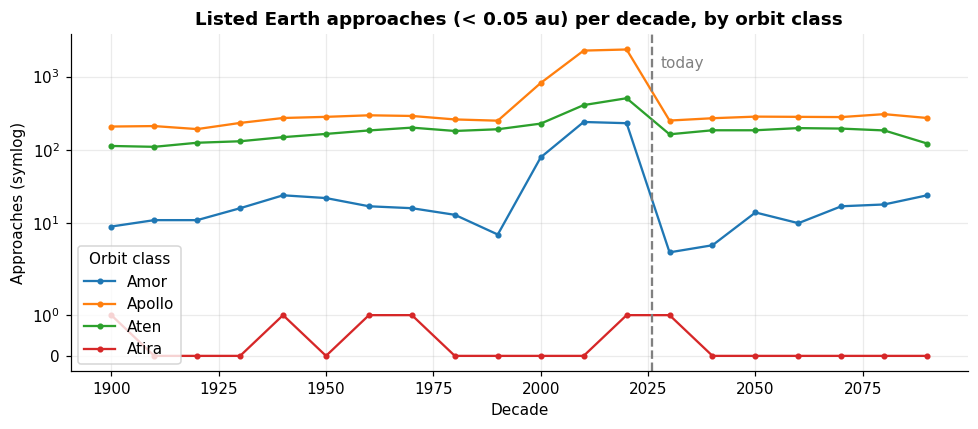

In [ ]:
dec_tot = fa.groupby("decade").size()
this_year = pd.Timestamp.now().year

fig, ax = plt.subplots(figsize=(9, 4))
for oc, grp in fa.groupby("orbit_class"):
    per_decade = grp.groupby("decade").size().reindex(dec_tot.index, fill_value=0)
    ax.plot(per_decade, marker="o", ms=3, lw=1.5, label=oc)

ax.set_yscale("symlog")
ax.axvline(this_year, color="grey", ls="--")
ax.text(this_year + 2, ax.get_ylim()[1] * .5, "today", color="grey", va="top")
ax.set_title("Listed Earth approaches (< 0.05 au) per decade, by orbit class")
ax.set_xlabel("Decade")
ax.set_ylabel("Approaches (symlog)")
ax.legend(title="Orbit class")
savefig("insight1_decade")

In [ ]:
past = dec_tot[dec_tot.index < 1960].mean()
recent = dec_tot[(dec_tot.index >= 2000) & (dec_tot.index < 2020)].mean()
ratio1 = recent / max(past, 1)

if ratio1 >= 1.5:
    t1 = "Real encounter frequency does not change like that; the difference reflects when objects were discovered (later decades also include projected passes), so `approach_count` and `approaches_per_decade` partly measure how well an object is observed."
else:
    t1 = "The listed rate is roughly flat in this sample, so discovery bias is not the dominant pattern here; it remains a caveat for the count features."

display(Markdown(f"**Insight 1 - listed approaches per decade.** The 2000-2019 decades average **{recent:,.0f}** listed approaches against **{past:,.0f}** before 1960 ({ratio1:.1f}x). " + t1))

**Insight 1 - listed approaches per decade.** The 2000-2019 decades average **2,016** listed approaches against **381** before 1960 (5.3x). Real encounter frequency does not change like that; the difference reflects when objects were discovered (later decades also include projected passes), so `approach_count` and `approaches_per_decade` partly measure how well an object is observed.

### Insight 2 - hazard rate vs absolute magnitude H

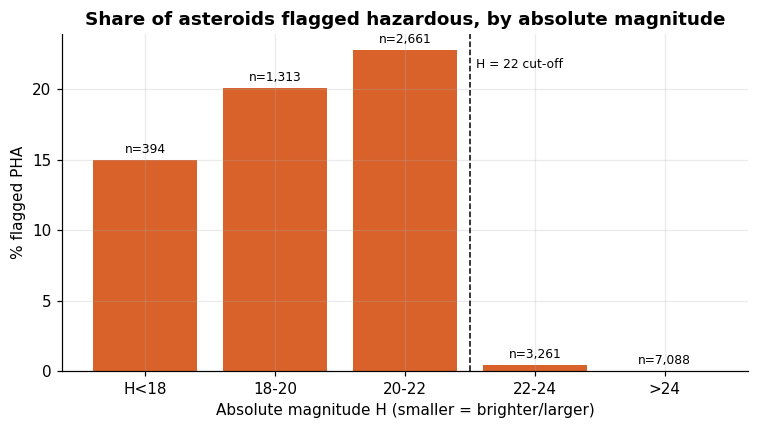

In [ ]:
bins = [0, 18, 20, 22, 24, 40]
labels = ["H<18", "18-20", "20-22", "22-24", ">24"]
dim["h_bin"] = pd.cut(dim["absolute_magnitude_h"], bins, labels=labels)
rate = dim.groupby("h_bin", observed=True)["is_potentially_hazardous"].agg(["mean", "size"])

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(rate.index.astype(str), rate["mean"] * 100, color=C_PHA)
for b, n in zip(bars, rate["size"]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + .5, f"n={n:,}", ha="center", fontsize=8)

ax.axvline(2.5, color="k", ls="--", lw=1)
ax.text(2.55, ax.get_ylim()[1] * .9, "H = 22 cut-off", fontsize=8)
ax.set_title("Share of asteroids flagged hazardous, by absolute magnitude")
ax.set_ylabel("% flagged PHA")
ax.set_xlabel("Absolute magnitude H (smaller = brighter/larger)")
savefig("insight2_h_rate")

In [ ]:
le22 = dim[dim["absolute_magnitude_h"] <= PHA_H_MAX]
gt22 = dim[dim["absolute_magnitude_h"] > PHA_H_MAX]
r_le = le22["is_potentially_hazardous"].mean()

if r_le < 0.5:
    t2 = " Being large enough is necessary but far from sufficient: the orbit must also pass within 0.05 au."
else:
    t2 = ""

display(Markdown(f"**Insight 2 - hazard rate by brightness.** **{r_le:.1%}** of the {len(le22):,} objects with H <= 22 are flagged hazardous, against **{gt22['is_potentially_hazardous'].mean():.1%}** of the {len(gt22):,} fainter objects "
                 f"({int(gt22['is_potentially_hazardous'].sum())} flagged; by definition this should be 0, so any non-zero value is a label inconsistency already counted in the cleaning log)." + t2))

**Insight 2 - hazard rate by brightness.** **21.3%** of the 4,368 objects with H <= 22 are flagged hazardous, against **0.1%** of the 10,405 fainter objects (14 flagged; by definition this should be 0, so any non-zero value is a label inconsistency already counted in the cleaning log). Being large enough is necessary but far from sufficient: the orbit must also pass within 0.05 au.

### Insight 3 - minimum miss distance vs MOID

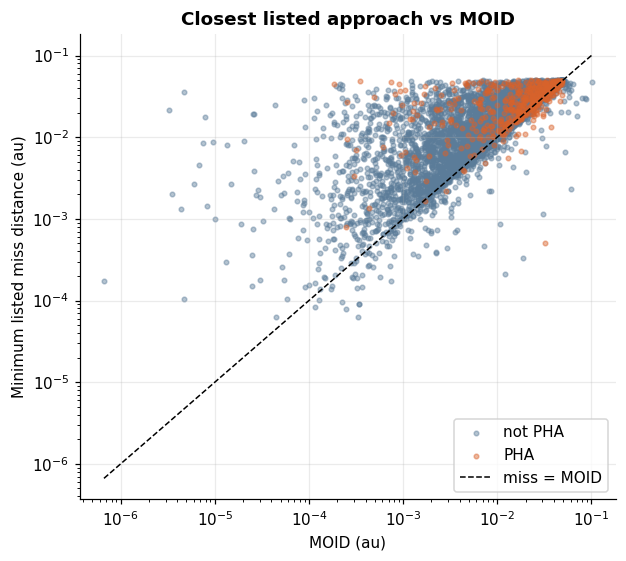

In [ ]:
sc = dim.dropna(subset=["min_miss_au", "moid_au"])
sc = sc[(sc["min_miss_au"] > 0) & (sc["moid_au"] > 0)]

fig, ax = plt.subplots(figsize=(5.8, 5.2))
for flag, col, lab in [(0, C_NON, "not PHA"), (1, C_PHA, "PHA")]:
    s = sc[sc["is_potentially_hazardous"] == flag]
    ax.scatter(s["moid_au"], s["min_miss_au"], s=9, alpha=.45, color=col, label=lab)

lim = [min(sc["moid_au"].min(), sc["min_miss_au"].min()),
       max(sc["moid_au"].max(), sc["min_miss_au"].max())]
ax.plot(lim, lim, "k--", lw=1, label="miss = MOID")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Closest listed approach vs MOID")
ax.set_xlabel("MOID (au)")
ax.set_ylabel("Minimum listed miss distance (au)")
ax.legend()
savefig("insight3_miss_vs_moid")

In [ ]:
below = (sc["min_miss_au"] < sc["moid_au"] * 0.98).mean()

if below < 0.5:
    t3 = "Most objects sit on or above the diagonal, so the minimum miss distance in the 'kinematic' feature set carries much of the MOID condition. "
else:
    t3 = "Many objects sit below the diagonal here, so the bound is loose in this data. "

display(Markdown(f"**Insight 3 - the 'kinematic' features are not independent of MOID.** An actual approach cannot be closer than the orbit-intersection distance, so the minimum miss distance is an upper bound on MOID. "
                 f"Among {len(sc):,} objects with both values, **{below:.1%}** fall below the diagonal (closer than the stored MOID, which can happen because MOID evolves over the 200-year window). "
                 + t3 + "This is why a velocity-only ablation is added in Section 7."))

**Insight 3 - the 'kinematic' features are not independent of MOID.** An actual approach cannot be closer than the orbit-intersection distance, so the minimum miss distance is an upper bound on MOID. Among 6,608 objects with both values, **8.1%** fall below the diagonal (closer than the stored MOID, which can happen because MOID evolves over the 200-year window). Most objects sit on or above the diagonal, so the minimum miss distance in the 'kinematic' feature set carries much of the MOID condition. This is why a velocity-only ablation is added in Section 7.

### Insight 4 - hazard flag vs the Sentry list

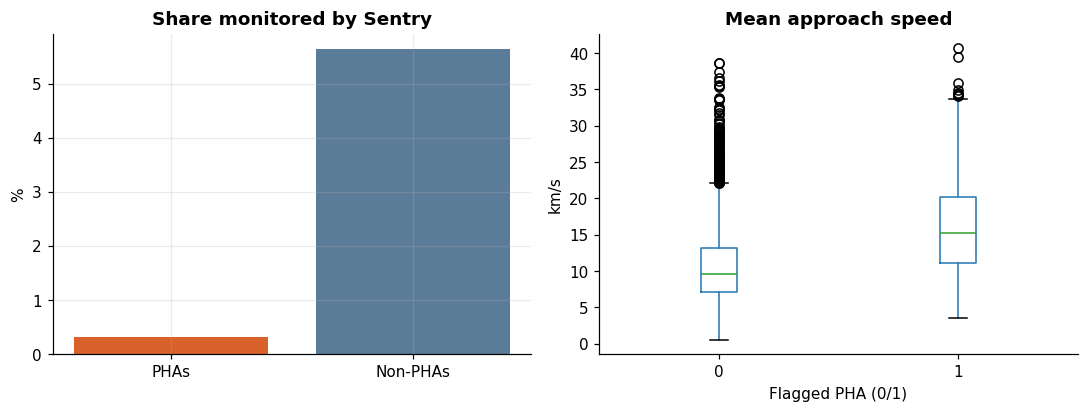

In [ ]:
ct = pd.crosstab(dim["is_potentially_hazardous"], dim["is_sentry_monitored"])
p_sen_pha = dim.loc[dim["is_potentially_hazardous"] == 1, "is_sentry_monitored"].mean()
p_pha_sen = dim.loc[dim["is_sentry_monitored"] == 1, "is_potentially_hazardous"].mean()
p_sen_non = dim.loc[dim["is_potentially_hazardous"] == 0, "is_sentry_monitored"].mean()

fig, axs = plt.subplots(1, 2, figsize=(10, 4))

# left: share monitored by Sentry
axs[0].bar(["PHAs", "Non-PHAs"], [p_sen_pha * 100, p_sen_non * 100], color=[C_PHA, C_NON])
axs[0].set_title("Share monitored by Sentry")
axs[0].set_ylabel("%")

# right: approach speed boxplot
dim.boxplot(column="mean_v_kms", by="is_potentially_hazardous", ax=axs[1], grid=False)
axs[1].set_title("Mean approach speed")
axs[1].set_xlabel("Flagged PHA (0/1)")
axs[1].set_ylabel("km/s")
fig.suptitle("")
savefig("insight4_sentry")

In [ ]:
v0 = dim.loc[dim["is_potentially_hazardous"] == 0, "mean_v_kms"].median()
v1 = dim.loc[dim["is_potentially_hazardous"] == 1, "mean_v_kms"].median()

display(Markdown(f"**Insight 4 - hazard flag versus the Sentry impact-risk list.** **{p_sen_pha:.1%}** of PHAs are on the Sentry list, and **{p_pha_sen:.1%}** of Sentry objects are PHAs. "
                 f"Sentry is about computed impact probability for individual orbits, PHA is a size-and-geometry screen, so they answer different questions. Median approach speed is {v1:.1f} km/s for PHAs vs {v0:.1f} km/s for others."))

**Insight 4 - hazard flag versus the Sentry impact-risk list.** **0.3%** of PHAs are on the Sentry list, and **0.4%** of Sentry objects are PHAs. Sentry is about computed impact probability for individual orbits, PHA is a size-and-geometry screen, so they answer different questions. Median approach speed is 15.2 km/s for PHAs vs 9.6 km/s for others.

### Insight 5 - PHA rate by orbit class

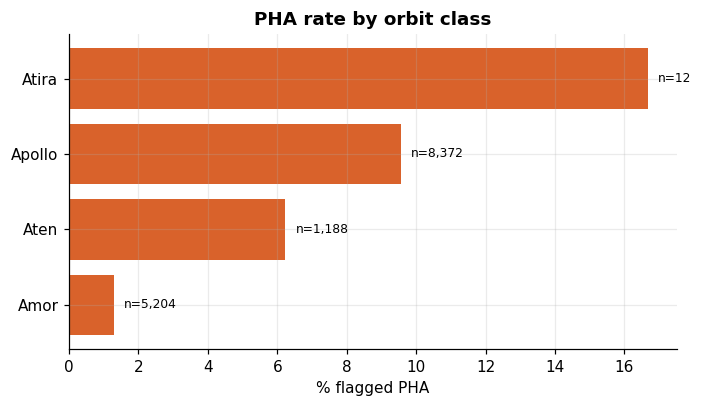

In [ ]:
oc = dim.groupby("orbit_class")["is_potentially_hazardous"].agg(["mean", "sum", "size"]).sort_values("mean", ascending=False)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.barh(oc.index, oc["mean"] * 100, color=C_PHA)
ax.invert_yaxis()
for i, (m, n) in enumerate(zip(oc["mean"], oc["size"])):
    ax.text(m * 100 + .3, i, f"n={n:,}", va="center", fontsize=8)
ax.set_title("PHA rate by orbit class")
ax.set_xlabel("% flagged PHA")
savefig("insight5_orbit_class")

In [ ]:
spread5 = oc["mean"].max() / max(oc["mean"].min(), 1e-9)

if spread5 >= 2:
    t5 = "Hazard is concentrated in a few orbit families. "
else:
    t5 = "The rate is fairly even across orbit classes in this sample. "

display(Markdown(f"**Insight 5 - PHA rate by orbit class.** {t5}{oc.index[0]} objects have the highest rate (**{oc['mean'].iloc[0]:.1%}**, {int(oc['sum'].iloc[0]):,} of {int(oc['size'].iloc[0]):,}); "
                 f"{oc.index[-1]} objects the lowest (**{oc['mean'].iloc[-1]:.1%}**). Orbit class follows from perihelion/aphelion geometry, which is also what drives MOID."))

**Insight 5 - PHA rate by orbit class.** Hazard is concentrated in a few orbit families. Atira objects have the highest rate (**16.7%**, 2 of 12); Amor objects the lowest (**1.3%**). Orbit class follows from perihelion/aphelion geometry, which is also what drives MOID.

## 7. Machine learning

**Task.** Binary classification of `is_potentially_hazardous` at **one row per asteroid** (so close-approach rows of the same object can never straddle train and test).

**Feature sets** (the leakage experiment from the project plan, plus one ablation):

| Set | Features | Purpose |
|---|---|---|
| **A - Benchmark** | H, diameter min/max, minimum miss distance, mean velocity | Catalogue-style performance. H and diameter are the PHA rule itself (diameter is computed from H), so near-perfect scores here show rule reconstruction, not insight. |
| **B - Kinematic** | approach count, approaches per decade, mean/max/variance of velocity, min/mean miss distance, Sentry flag | Does encounter history alone carry signal once H and diameter are removed? |
| **C - Velocity + Sentry (ablation)** | mean/max/variance of velocity, Sentry flag | Insight 3 showed miss distance bounds MOID. Removing every distance-type feature tests what is left. |

**Models.** A `DummyClassifier` (floor), `LogisticRegression` (interpretable linear model) and `RandomForestClassifier` (non-linear interactions, built-in importances). Both real models use `class_weight="balanced"`. A non-learning reference rule (`H <= 22`) is also reported.

**Protocol.** Stratified 80/20 split; imputation (median, with missing-indicators), a `log1p` transform for the heavily skewed non-negative features, and scaling are all inside a `Pipeline`, so they are fit on training data only. 5-fold stratified cross-validation on the training split.
**Model choice** between logistic regression and random forest uses cross-validated F1 (so a flag-everything model cannot win on recall). **Recall is the headline metric**; to push it up, the decision threshold is tuned on *out-of-fold training predictions* to reach 90 % recall, then applied once to the untouched test set.

### 7.1 Load the data and define the feature sets

In [ ]:
# read the data back from the database
ml = pd.read_sql("SELECT * FROM dim_asteroid", conn)
TARGET = "is_potentially_hazardous"

In [ ]:
FEATURE_SETS = {
    "A_benchmark": ["absolute_magnitude_h", "diameter_km_min", "diameter_km_max", "min_miss_au", "mean_v_kms"],
    "B_kinematic": ["approach_count", "approaches_per_decade", "mean_v_kms", "max_v_kms",
                    "var_v_kms2", "min_miss_au", "mean_miss_au", "is_sentry_monitored"],
    "C_velocity_sentry": ["mean_v_kms", "max_v_kms", "var_v_kms2", "is_sentry_monitored"],
}

# all features used anywhere
allf = sorted({f for fs in FEATURE_SETS.values() for f in fs})
assert (ml[allf].min() >= 0).all(), "log1p requires non-negative features"

### 7.2 Train / test split

In [ ]:
train_idx, test_idx = train_test_split(ml.index, test_size=0.2, stratify=ml[TARGET], random_state=SEED)

ml["split"] = "train"
ml.loc[test_idx, "split"] = "test"

y_tr = ml.loc[train_idx, TARGET].values
y_te = ml.loc[test_idx, TARGET].values

print(f"train {len(train_idx):,} (PHA {y_tr.mean():.2%}) | test {len(test_idx):,} (PHA {y_te.mean():.2%}, {int(y_te.sum())} positives)")

train 11,820 (PHA 6.38%) | test 2,956 (PHA 6.39%, 189 positives)


### 7.3 Models, pipeline and cross-validation setup

In [ ]:
def make_models():
    return {
        "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=SEED),
        "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=SEED, n_jobs=-1),
    }

In [ ]:
def make_pipe(model):
    # imputing, log transform and scaling are inside the pipeline so they only learn from training data
    return Pipeline([
        ("impute", SimpleImputer(strategy="median", add_indicator=True)),
        ("log1p", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler()),
        ("model", model),
    ])

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

scoring = {
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
}

### 7.4 Evaluation helper functions

In [ ]:
def metrics(y, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "recall": tp / max(tp + fn, 1),
        "precision": tp / max(tp + fp, 1),
        "f1": f1_score(y, pred, zero_division=0),
        "roc_auc": roc_auc_score(y, proba),
        "pr_auc": average_precision_score(y, proba),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

In [ ]:
def wilson(k, n, z=1.96):
    # Wilson confidence interval for a proportion
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z * z / n
    c = p + z * z / (2 * n)
    r = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return ((c - r) / d, (c + r) / d)

In [ ]:
def tune_threshold(y, proba, target_recall=0.90):
    # highest threshold that still reaches the target recall
    prec, rec, thr = precision_recall_curve(y, proba)
    ok = np.where(rec[:-1] >= target_recall)[0]
    if len(ok):
        return float(thr[ok[-1]])
    return 0.0

### 7.5 Train every model on every feature set

In [ ]:
cv_rows = []
test_rows = []
fitted = {}
test_proba = {}
thresholds = {}

for fs_name, feats in FEATURE_SETS.items():
    Xtr = ml.loc[train_idx, feats]
    Xte = ml.loc[test_idx, feats]

    for mname, model in make_models().items():
        pipe = make_pipe(model)

        # 5-fold cross-validation on the training split
        res = cross_validate(pipe, Xtr, y_tr, cv=cv, scoring=scoring)
        cv_row = {"feature_set": fs_name, "model": mname}
        for k in scoring:
            cv_row[f"cv_{k}"] = res[f"test_{k}"].mean()
        for k in scoring:
            cv_row[f"cv_{k}_sd"] = res[f"test_{k}"].std()
        cv_rows.append(cv_row)

        # fit on all training data and predict the test set
        pipe.fit(Xtr, y_tr)
        proba = pipe.predict_proba(Xte)[:, 1]
        fitted[(fs_name, mname)] = pipe
        test_proba[(fs_name, mname)] = proba

        test_rows.append({"feature_set": fs_name, "model": mname, "threshold_policy": "0.50",
                          "threshold": 0.5, **metrics(y_te, proba, 0.5)})

        # for the two real models also tune the threshold for 90% recall
        if mname in ("Logistic Regression", "Random Forest"):
            oof = cross_val_predict(make_pipe(make_models()[mname]), Xtr, y_tr, cv=cv, method="predict_proba")[:, 1]
            thr = tune_threshold(y_tr, oof, 0.90)
            thresholds[(fs_name, mname)] = thr
            test_rows.append({"feature_set": fs_name, "model": mname,
                              "threshold_policy": "tuned for 90% recall (train OOF)",
                              "threshold": thr, **metrics(y_te, proba, thr)})

cv_df = pd.DataFrame(cv_rows)
test_df = pd.DataFrame(test_rows)

### 7.6 Reference rule (H <= 22, no learning)

In [ ]:
rule_pred = (ml.loc[test_idx, "absolute_magnitude_h"] <= PHA_H_MAX).fillna(False).astype(int).values
tn, fp, fn, tp = confusion_matrix(y_te, rule_pred, labels=[0, 1]).ravel()

rule_row = {
    "feature_set": "Reference", "model": "Rule: H <= 22 (no learning)",
    "threshold_policy": "fixed", "threshold": np.nan,
    "recall": tp / max(tp + fn, 1),
    "precision": tp / max(tp + fp, 1),
    "f1": f1_score(y_te, rule_pred, zero_division=0),
    "roc_auc": np.nan, "pr_auc": np.nan,
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
}
test_df = pd.concat([test_df, pd.DataFrame([rule_row])], ignore_index=True)

### 7.7 Results tables

In [ ]:
fmt = lambda m, s: f"{m:.3f} +/- {s:.3f}"

# nicer "mean +/- sd" columns for display
cv_show = cv_df.copy()
for k in ["cv_recall", "cv_precision", "cv_f1", "cv_roc_auc", "cv_pr_auc"]:
    new_col = k.replace("cv_", "CV ")
    cv_show[new_col] = cv_df.apply(lambda r: fmt(r[k], r[k + "_sd"]), axis=1)

print("5-fold cross-validation on the training split (mean +/- sd):")
display(cv_show[["feature_set", "model", "CV recall", "CV precision", "CV f1", "CV roc_auc", "CV pr_auc"]])

5-fold cross-validation on the training split (mean +/- sd):


,feature_set,model,CV recall,CV precision,CV f1,CV roc_auc,CV pr_auc
0,A_benchmark,Dummy (stratified),0.048 +/- 0.017,0.046 +/- 0.016,0.047 +/- 0.017,0.490 +/- 0.009,0.063 +/- 0.001
1,A_benchmark,Dummy (most frequent),0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000,0.064 +/- 0.000
2,A_benchmark,Logistic Regression,0.901 +/- 0.016,0.225 +/- 0.005,0.360 +/- 0.007,0.939 +/- 0.005,0.684 +/- 0.041
3,A_benchmark,Random Forest,0.699 +/- 0.030,0.347 +/- 0.020,0.463 +/- 0.019,0.880 +/- 0.011,0.658 +/- 0.022
4,B_kinematic,Dummy (stratified),0.048 +/- 0.017,0.046 +/- 0.016,0.047 +/- 0.017,0.490 +/- 0.009,0.063 +/- 0.001
5,B_kinematic,Dummy (most frequent),0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000,0.064 +/- 0.000
6,B_kinematic,Logistic Regression,0.504 +/- 0.022,0.222 +/- 0.010,0.308 +/- 0.013,0.759 +/- 0.012,0.287 +/- 0.042
7,B_kinematic,Random Forest,0.118 +/- 0.013,0.531 +/- 0.072,0.193 +/- 0.020,0.592 +/- 0.016,0.153 +/- 0.003
8,C_velocity_sentry,Dummy (stratified),0.048 +/- 0.017,0.046 +/- 0.016,0.047 +/- 0.017,0.490 +/- 0.009,0.063 +/- 0.001
9,C_velocity_sentry,Dummy (most frequent),0.000 +/- 0.000,0.000 +/- 0.000,0.000 +/- 0.000,0.500 +/- 0.000,0.064 +/- 0.000


In [ ]:
print("Held-out test set:")
display(test_df.round(3))

Held-out test set:


,feature_set,model,threshold_policy,threshold,recall,precision,f1,roc_auc,pr_auc,TN,FP,FN,TP
0,A_benchmark,Dummy (stratified),0.50,0.500,0.048,0.044,0.046,0.489,0.063,2572,195,180,9
1,A_benchmark,Dummy (most frequent),0.50,0.500,0.000,0.000,0.000,0.500,0.064,2767,0,189,0
2,A_benchmark,Logistic Regression,0.50,0.500,0.868,0.227,0.360,0.936,0.644,2210,557,25,164
3,A_benchmark,Logistic Regression,tuned for 90% recall (train OOF),0.506,0.862,0.228,0.361,0.936,0.644,2216,551,26,163
4,A_benchmark,Random Forest,0.50,0.500,0.698,0.354,0.470,0.873,0.642,2526,241,57,132
5,A_benchmark,Random Forest,tuned for 90% recall (train OOF),0.000,1.000,0.064,0.120,0.873,0.642,0,2767,0,189
6,B_kinematic,Dummy (stratified),0.50,0.500,0.048,0.044,0.046,0.489,0.063,2572,195,180,9
7,B_kinematic,Dummy (most frequent),0.50,0.500,0.000,0.000,0.000,0.500,0.064,2767,0,189,0
8,B_kinematic,Logistic Regression,0.50,0.500,0.439,0.190,0.266,0.729,0.231,2414,353,106,83
9,B_kinematic,Logistic Regression,tuned for 90% recall (train OOF),0.424,0.942,0.083,0.153,0.729,0.231,802,1965,11,178


### 7.8 Choose the best model per feature set

In [ ]:
# model selection per feature set by CV F1 among the two real models
real = cv_df[cv_df["model"].isin(["Logistic Regression", "Random Forest"])]

selected = {}
for fs in FEATURE_SETS:
    best = real[real["feature_set"] == fs].sort_values("cv_f1", ascending=False).iloc[0]
    selected[fs] = best["model"]

print("Selected model per feature set (by CV F1):", selected)

Selected model per feature set (by CV F1): {'A_benchmark': 'Random Forest', 'B_kinematic': 'Logistic Regression', 'C_velocity_sentry': 'Logistic Regression'}


### 7.9 Confusion matrices

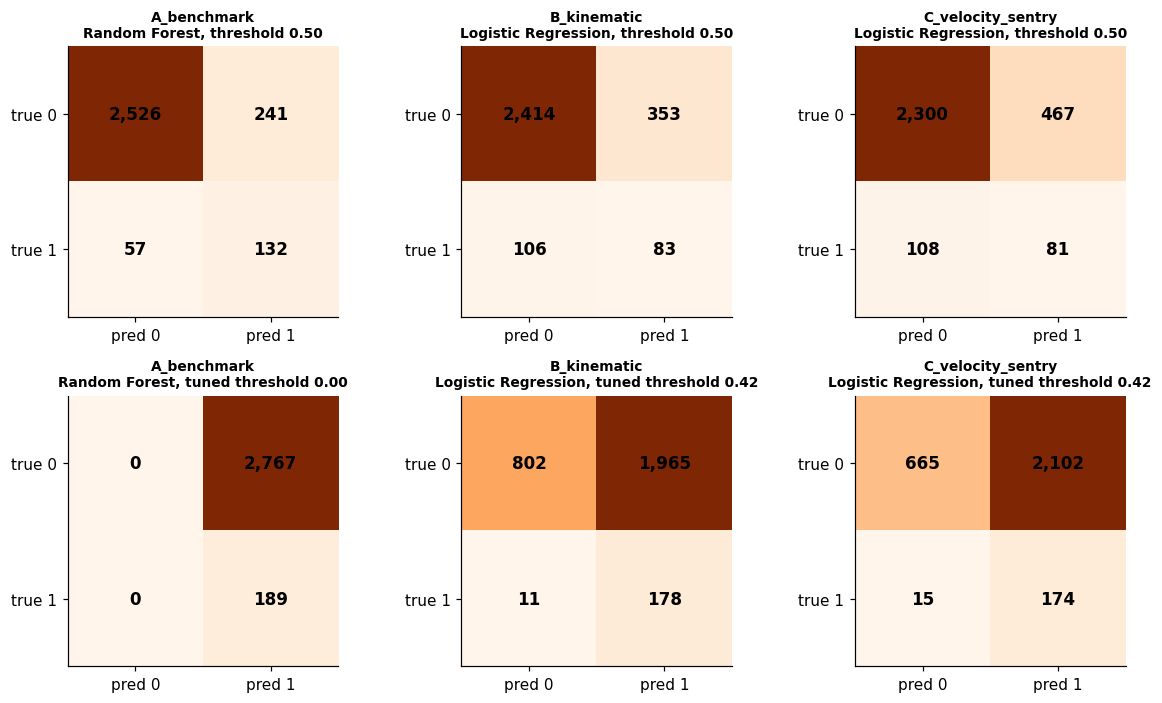

In [ ]:
fig, axs = plt.subplots(2, 3, figsize=(11, 6.5))

for j, fs in enumerate(FEATURE_SETS):
    m = selected[fs]
    proba = test_proba[(fs, m)]
    tuned_thr = thresholds[(fs, m)]

    for i, (thr, ttl) in enumerate([(0.5, "threshold 0.50"), (tuned_thr, f"tuned threshold {tuned_thr:.2f}")]):
        cm = confusion_matrix(y_te, (proba >= thr).astype(int), labels=[0, 1])
        axs[i, j].imshow(cm, cmap="Oranges")
        for (r, c), v in np.ndenumerate(cm):
            axs[i, j].text(c, r, f"{v:,}", ha="center", va="center", fontsize=11, fontweight="bold")
        axs[i, j].set_xticks([0, 1], ["pred 0", "pred 1"])
        axs[i, j].set_yticks([0, 1], ["true 0", "true 1"])
        axs[i, j].grid(False)
        axs[i, j].set_title(f"{fs}\n{m}, {ttl}", fontsize=9)

savefig("ml_confusion_matrices")

### 7.10 Precision-recall curves

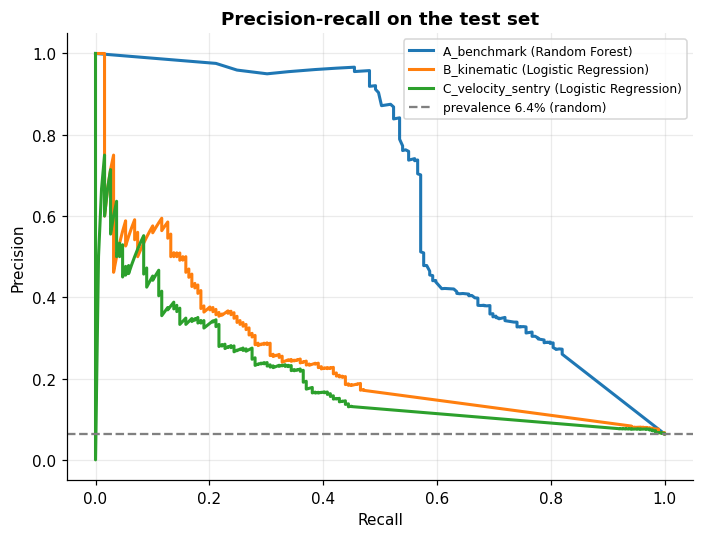

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 5))

for fs in FEATURE_SETS:
    p, r, _ = precision_recall_curve(y_te, test_proba[(fs, selected[fs])])
    ax.plot(r, p, lw=2, label=f"{fs} ({selected[fs]})")

ax.axhline(y_te.mean(), color="grey", ls="--", label=f"prevalence {y_te.mean():.1%} (random)")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-recall on the test set")
ax.legend(fontsize=8)
savefig("ml_pr_curves")

### 7.11 Feature importance (random forest Gini + permutation importance on test)

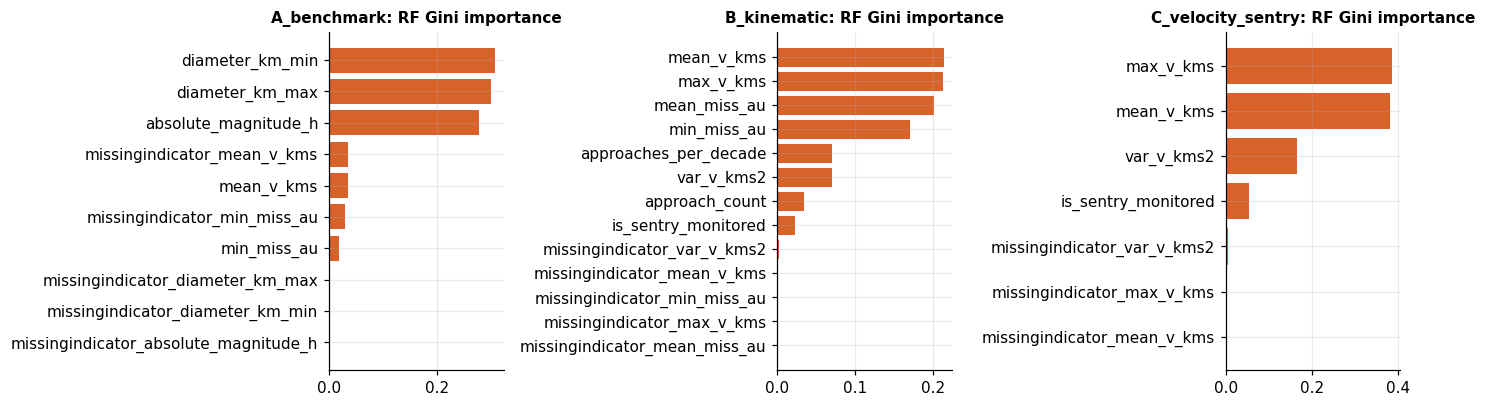

In [ ]:
imp_rows = []
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))

for j, (fs, feats) in enumerate(FEATURE_SETS.items()):
    pipe = fitted[(fs, "Random Forest")]
    names = pipe.named_steps["impute"].get_feature_names_out(feats)
    gini = pipe.named_steps["model"].feature_importances_
    perm = permutation_importance(pipe, ml.loc[test_idx, feats], y_te,
                                  scoring="average_precision", n_repeats=15, random_state=SEED)

    for f, gv in zip(names, gini):
        if f in feats:
            perm_value = perm.importances_mean[list(feats).index(f)]
        else:
            perm_value = np.nan   # missing-indicator columns have no permutation score
        imp_rows.append({"feature_set": fs, "feature": f, "gini_importance": gv, "permutation_importance": perm_value})

    order = np.argsort(gini)
    axs[j].barh(np.array(names)[order], gini[order], color=C_PHA)
    axs[j].set_title(f"{fs}: RF Gini importance", fontsize=10)

savefig("ml_feature_importance")

In [ ]:
importance_df = pd.DataFrame(imp_rows)
display(importance_df.round(4))

,feature_set,feature,gini_importance,permutation_importance
0,A_benchmark,absolute_magnitude_h,0.2759,0.0168
1,A_benchmark,diameter_km_min,0.3068,0.0159
2,A_benchmark,diameter_km_max,0.2989,0.0290
3,A_benchmark,min_miss_au,0.0191,0.1578
4,A_benchmark,mean_v_kms,0.0343,0.1703
5,A_benchmark,missingindicator_absolute_magnitude_h,0.0000,NaN
6,A_benchmark,missingindicator_diameter_km_min,0.0000,NaN
7,A_benchmark,missingindicator_diameter_km_max,0.0000,NaN
8,A_benchmark,missingindicator_min_miss_au,0.0293,NaN
9,A_benchmark,missingindicator_mean_v_kms,0.0357,NaN


### 7.12 Reading the results

In [ ]:
def get(fs, policy):
    # test-set row for the selected model of a feature set
    r = test_df[(test_df.feature_set == fs) & (test_df.model == selected[fs]) & (test_df.threshold_policy.str.startswith(policy))].iloc[0]
    return r

In [ ]:
prev = y_te.mean()
lines = []

for fs in FEATURE_SETS:
    r5 = get(fs, "0.50")
    rt = get(fs, "tuned")
    lo, hi = wilson(int(rt.TP), int(rt.TP + rt.FN))
    lines.append(f"- **{fs}** ({selected[fs]}): at 0.50 recall **{r5.recall:.2f}**, precision {r5.precision:.2f}, F1 {r5.f1:.2f}, PR-AUC {r5.pr_auc:.3f}, ROC-AUC {r5.roc_auc:.3f}. "
                 f"With the tuned threshold recall rises to **{rt.recall:.2f}** (95% Wilson interval {lo:.2f}-{hi:.2f}, n={int(rt.TP + rt.FN)} positives) at precision {rt.precision:.2f}, meaning {int(rt.FP)} false alarms against {int(rt.TP)} hits.")

In [ ]:
# rows we need for the paragraphs below
fs_names = list(FEATURE_SETS)
A = get(fs_names[0], "0.50")
B = get(fs_names[1], "0.50")
Cc = get(fs_names[2], "0.50")
base = test_df[(test_df.feature_set == "B_kinematic") & (test_df.model == "Dummy (stratified)")].iloc[0]
rule = test_df[test_df.model.str.startswith("Rule")].iloc[0]

text = ["### Reading the results", *lines, ""]

In [ ]:
# benchmark paragraph
if A.pr_auc > 0.9:
    bench_text = (f"This is near-perfect and should not be read as predictive skill: H and diameter *are* the hazard rule (the single threshold H <= 22 alone gives recall "
                  f"{rule.recall:.2f} and precision {rule.precision:.2f}). ")
else:
    bench_text = f"The H <= 22 rule alone gives recall {rule.recall:.2f} and precision {rule.precision:.2f}. "

text.append(f"**Benchmark (A).** PR-AUC {A.pr_auc:.3f} versus a prevalence of {prev:.1%}. " + bench_text + "A ceiling, not a finding.")

In [ ]:
# kinematic paragraph
drop = A.pr_auc - B.pr_auc

if B.pr_auc > 0.6:
    kin_text = "Encounter history carries strong signal, but Insight 3 explains most of it: the minimum miss distance is bounded by MOID, so B still contains much of the MOID condition. "
else:
    kin_text = "Without size information the model recovers only part of the hazard definition. "

text.append(f"**Kinematic (B).** Removing H and diameter changes PR-AUC by {-drop:+.3f} ({B.pr_auc:.3f}). " + kin_text +
            f"The stratified-dummy baseline reaches PR-AUC {base.pr_auc:.3f}, so B's lift over chance is {B.pr_auc / max(prev, 1e-9):.1f}x.")

In [ ]:
# velocity + sentry paragraph
if Cc.pr_auc > 1.5 * prev:
    c_text = "There is some signal beyond chance, but it is weak: speed and Sentry membership describe orbit shape and discovery priority more than the PHA rule."
else:
    c_text = "Essentially no usable signal remains, which answers the research question: the predictive power of encounter data comes from proximity and size information, not from speed or monitoring status."

text.append(f"**Velocity + Sentry ablation (C).** With every distance-type feature removed, PR-AUC is {Cc.pr_auc:.3f} ({Cc.pr_auc / max(prev, 1e-9):.1f}x prevalence). " + c_text)

In [ ]:
# warning if the tuned threshold only works by flagging nearly everything
degenerate = [fs for fs in FEATURE_SETS if get(fs, "tuned").precision <= prev * 1.1 and get(fs, "tuned").recall > 0.97]

if degenerate:
    text.append(f"**Warning.** For {', '.join(degenerate)} the tuned threshold reaches its recall target only by flagging almost every asteroid (precision is about the {prev:.1%} prevalence). That is a failure to separate the classes, not a useful screening rule; prefer the 0.50 result there.")

text.append(f"**Trade-off.** The tuned threshold buys recall at the cost of precision; because the PHA class is only {prev:.1%} of objects, even a good model produces many false alarms. In hazard screening that cost is acceptable (follow-up observation is cheap), but the false-alarm counts above show the price. Conclusions about small differences are limited by the test set having only {int(y_te.sum())} positives.")

In [ ]:
display(Markdown("\n\n".join(text)))

### Reading the results

- **A_benchmark** (Random Forest): at 0.50 recall **0.70**, precision 0.35, F1 0.47, PR-AUC 0.642, ROC-AUC 0.873. With the tuned threshold recall rises to **1.00** (95% Wilson interval 0.98-1.00, n=189 positives) at precision 0.06, meaning 2767 false alarms against 189 hits.

- **B_kinematic** (Logistic Regression): at 0.50 recall **0.44**, precision 0.19, F1 0.27, PR-AUC 0.231, ROC-AUC 0.729. With the tuned threshold recall rises to **0.94** (95% Wilson interval 0.90-0.97, n=189 positives) at precision 0.08, meaning 1965 false alarms against 178 hits.

- **C_velocity_sentry** (Logistic Regression): at 0.50 recall **0.43**, precision 0.15, F1 0.22, PR-AUC 0.191, ROC-AUC 0.684. With the tuned threshold recall rises to **0.92** (95% Wilson interval 0.87-0.95, n=189 positives) at precision 0.08, meaning 2102 false alarms against 174 hits.



**Benchmark (A).** PR-AUC 0.642 versus a prevalence of 6.4%. The H <= 22 rule alone gives recall 1.00 and precision 0.22. A ceiling, not a finding.

**Kinematic (B).** Removing H and diameter changes PR-AUC by -0.411 (0.231). Without size information the model recovers only part of the hazard definition. The stratified-dummy baseline reaches PR-AUC 0.063, so B's lift over chance is 3.6x.

**Velocity + Sentry ablation (C).** With every distance-type feature removed, PR-AUC is 0.191 (3.0x prevalence). There is some signal beyond chance, but it is weak: speed and Sentry membership describe orbit shape and discovery priority more than the PHA rule.

**Warning.** For A_benchmark the tuned threshold reaches its recall target only by flagging almost every asteroid (precision is about the 6.4% prevalence). That is a failure to separate the classes, not a useful screening rule; prefer the 0.50 result there.

**Trade-off.** The tuned threshold buys recall at the cost of precision; because the PHA class is only 6.4% of objects, even a good model produces many false alarms. In hazard screening that cost is acceptable (follow-up observation is cheap), but the false-alarm counts above show the price. Conclusions about small differences are limited by the test set having only 189 positives.

In [ ]:
# add the ML decisions to the cleaning log
log_step("ML", "Features contain missing values (no approach, missing H)", int(ml[allf].isna().any(axis=1).sum()), "impute inside pipeline",
         "Median imputation with missing-indicators, fit on training folds only; indicators preserve the fact that no approach occurred.")
log_step("ML", "Heavily skewed non-negative features (counts, diameter, variance)", len(allf), "log1p + StandardScaler in pipeline",
         "Helps the linear model; harmless for trees. Fit on training data only.")
log_step("ML", "Class imbalance", int(ml[TARGET].sum()), "class_weight='balanced', PR-AUC, recall",
         "Accuracy would exceed 90% for a model that predicts 'safe' every time.")

### 7.13 Model outputs for Power BI

In [ ]:
# predictions for every asteroid, for each feature set's selected model
pred_rows = []

for fs, feats in FEATURE_SETS.items():
    m = selected[fs]
    pipe = fitted[(fs, m)]
    thr = thresholds[(fs, m)]

    proba_all = pipe.predict_proba(ml[feats])[:, 1]
    d = pd.DataFrame({"asteroid_id": ml["asteroid_id"], "feature_set": fs, "model": m,
                      "split": ml["split"], "actual": ml[TARGET], "pha_probability": proba_all})

    d["predicted_at_0_50"] = (d["pha_probability"] >= 0.5).astype(int)
    d["predicted_tuned"] = (d["pha_probability"] >= thr).astype(int)
    d["outcome_tuned"] = np.select([(d.actual == 1) & (d.predicted_tuned == 1),
                                    (d.actual == 0) & (d.predicted_tuned == 1),
                                    (d.actual == 1) & (d.predicted_tuned == 0)],
                                   ["TP", "FP", "FN"], "TN")
    pred_rows.append(d)

pred_df = pd.concat(pred_rows, ignore_index=True)

In [ ]:
metrics_out = pd.concat([test_df.assign(stage="test"), cv_df.assign(stage="cv_train")], ignore_index=True)

# save ML tables to the database and as csv
for name, df in [("ml_predictions", pred_df), ("ml_metrics_test", test_df),
                 ("ml_metrics_cv", cv_df), ("ml_feature_importance", importance_df)]:
    sql_ready(df).to_sql(name, conn, if_exists="replace", index=False)
    df.to_csv(CLEAN_DIR / f"{name}.csv", index=False)

conn.commit()

In [ ]:
# check that all predictions belong to an asteroid in the dimension table
orphans = conn.execute("SELECT COUNT(*) FROM ml_predictions p LEFT JOIN dim_asteroid d USING(asteroid_id) WHERE d.asteroid_id IS NULL").fetchone()[0]
assert orphans == 0

print("ML tables stored:", [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='table' AND name LIKE 'ml_%'")])

ML tables stored: ['ml_predictions', 'ml_metrics_test', 'ml_metrics_cv', 'ml_feature_importance']


## 8. Cleaning and transformation log, and outputs for Power BI

In [ ]:
# show the full cleaning log and save it
log_df = pd.DataFrame(CLEANING_LOG)
display(log_df)

log_df.to_csv(CLEAN_DIR / "cleaning_log.csv", index=False)

,step,source,issue_found,count,action,rationale
0,1,CAD,All numeric fields delivered as strings,10,convert,"to_numeric with errors='coerce'; 4 values became NaN through failed parsing,..."
1,2,CAD,Leading whitespace in fullname (e.g. ' (2020 AY1)'),43623,convert,strip(); harmless but breaks string joins and slicers.
2,3,CAD,"Date strings like '2020-Jan-01 00:54' (TDB time scale, English month names)",43623,convert,Parsed to datetime (0 failed to parse); cross-checked against the Julian-dat...
3,4,CAD,"t_sigma_f is a formatted text field ('< 00:01', 'dd_hh:mm', '~...')",0,convert / keep NaN,Parsed to minutes; the '<' and '~' qualifiers are dropped. Unparseable value...
4,5,CAD,"Rows missing designation, distance, velocity or date",0,drop,Cannot be attributed to an asteroid or used for any feature.
5,6,CAD,Duplicate close approaches (same asteroid and same Julian date; decade windo...,0,drop,Keep first; an event cannot happen twice and would inflate approach counts.
6,7,CAD,"dist outside its own [dist_min, dist_max] interval",0,flag,Kept: may be rounding; flagged so dashboards can exclude them.
7,8,CAD,"Non-positive distance or velocity, or v_rel above 72.8 km/s (physical maximu...",0,flag,Kept and flagged rather than deleted: extreme values need a physical explana...
8,9,CAD,Distances only in au,43623,derive,"Added lunar-distance column (au x 149.6M km / 384,400 km) because it is the ..."
9,10,Sentry,Numeric fields delivered as strings,9,convert,to_numeric(errors='coerce').


In [ ]:
# markdown version of the log
with open(CLEAN_DIR / "cleaning_log.md", "w", encoding="utf-8") as f:
    f.write("| # | Source | Issue found | Count | Action | Rationale |\n|---|---|---|---|---|---|\n")
    for r in CLEANING_LOG:
        f.write(f"| {r['step']} | {r['source']} | {r['issue_found']} | {r['count']:,} | {r['action']} | {r['rationale']} |\n")

# also store the log in the database
sql_ready(log_df).to_sql("cleaning_log", conn, if_exists="replace", index=False)
conn.commit()

In [ ]:
# list of output files
files = []
for p in sorted(DATA_DIR.rglob("*")):
    if p.is_file() and "raw/neows" not in str(p) and "raw/cad" not in str(p) and "partitioned" not in str(p):
        files.append({"file": str(p.relative_to(DATA_DIR)), "size_MB": round(p.stat().st_size / 1e6, 2)})

files = pd.DataFrame(files)
display(files)

,file,size_MB
0,clean/agg_decade_orbit_class.csv,0.00
1,clean/cleaning_log.csv,0.01
2,clean/cleaning_log.md,0.01
3,clean/dim_asteroid.csv,4.14
4,clean/fact_close_approach.csv,2.74
5,clean/fact_sentry.csv,0.06
6,clean/ml_feature_importance.csv,0.00
7,clean/ml_metrics_cv.csv,0.00
8,clean/ml_metrics_test.csv,0.00
9,clean/ml_predictions.csv,3.13


In [ ]:
conn.close()
print("Done. Database:", DB_PATH, "| figures:", FIG_DIR, "| log:", CLEAN_DIR / "cleaning_log.csv")

Done. Database: neo_project_data/clean/neo_wrangled.db | figures: neo_project_data/figures | log: neo_project_data/clean/cleaning_log.csv


**Power BI hand-off.** Connect Power BI to the flat CSVs in `clean/` (Power BI Desktop reads SQLite only through an ODBC driver; the CSVs hold identical data). Relationships: `fact_close_approach[asteroid_id]` and `fact_sentry[asteroid_id]` and `ml_predictions[asteroid_id]` all point to `dim_asteroid[asteroid_id]` (many-to-one). Suggested pages: **Overview** (Insights 1 and 5, decade slicer), **Drill-down** (asteroid table with size-class and orbit-class slicers, approach timeline), **Model insights** (confusion matrices, PR curve, feature importance from `ml_*` tables, filter `split = test`). The PNGs in `figures/` are ready for the report and slides.

## 9. Limitations and wrangling decisions that could bias conclusions

- **Sampling.** NeoWs was read through a seeded random sample of catalogue pages. The sample is approximately uniform over catalogue IDs, but any run with a different seed or catalogue update yields slightly different numbers; the sample share is printed in Section 3.
- **The label is an authority's output, not ground truth.** The PHA flag is a *definition* (H <= 22 and MOID <= 0.05 au), not a physical measurement of danger. Models learn the definition and its data-timing quirks (see the label/rule mismatch count), not real impact risk.
- **Size is modelled, not measured.** NeoWs diameters are computed from H with an assumed albedo range, so `diameter_km_min/max` are a re-expression of H. Feature set A therefore has built-in leakage; this is documented rather than hidden.
- **Distance features are bounded by MOID.** Even the "kinematic" set contains information equivalent to part of the MOID condition (Insight 3). The velocity-only ablation (set C) is the cleanest test of dynamic information alone.
- **CAD scope.** Only approaches within 0.05 au between 1900 and 2100 are listed, which censors the distance statistics (objects that never come that close have none) and mixes past observations with projected passes. Approach counts also reflect discovery history, not true encounter rates (Insight 1). Counts depend on this 0.05 au cut-off and window.
- **Imputation.** Missing H and distance statistics are imputed with training medians plus missing-indicators. The indicator for "no approach" is itself informative, which is correct (an object that never approaches is different) but means imputation is not neutral.
- **Snapshots.** Sentry and NeoWs change as new observations arrive; the NeoWs Sentry flag and the Sentry API can disagree (counted in the log). Results describe the snapshot in `raw/manifest.json`.
- **Statistical power.** The positive class is a few percent of objects, so the test set holds relatively few hazardous asteroids; recall intervals are wide and small differences between models are not reliable.
- **Dropped rows.** CAD approaches and Sentry objects outside the NeoWs sample were removed from the fact tables to keep foreign keys valid; they remain in the raw snapshot.